# Laboratorio 14 — Predicciones sobre grafos con ML tradicional

In [1]:
# === Importaciones de la biblioteca estándar ===
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from tqdm.notebook import tqdm

# === Importaciones científicas y de grafos ===
import numpy as np
import pandas as pd
import networkx as nx
from scipy.spatial import cKDTree
from scipy.sparse import triu

# === Importaciones de visualización ===
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import plotly.graph_objects as go

# === Importaciones de Aprendizaje Automático (scikit-learn) ===
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# === Interfaz y visualización de resultados ===
from IPython.display import display, Markdown
from tabulate import tabulate

def dMarkdown(text):
    """Muestra texto en formato Markdown en el notebook."""
    display(Markdown(text))

def dM_table(datos_tabla, headers):
    """Genera y muestra una tabla formateada en Markdown usando tabulate."""
    tabla_md = tabulate(
        datos_tabla,
        headers=headers,
        tablefmt="pipe"
    )
    dMarkdown(tabla_md)

## Cristal y líquido en un coloide real: nodos, relaciones y grafos

**Computación Científica Avanzada · Unidad 4, sesión 2**

En una muestra coloidal coexisten un cristal y un líquido. Con solo las posiciones medidas de las partículas, convertidas en un **grafo de vecinos**, vamos a responder una pregunta de cada una de las tres tareas de Hamilton §1.2:

| Parte | Tarea | Pregunta |
|---|---|---|
| A | Clasificación de nodos | ¿Es cristalina esta partícula? |
| B | Predicción de relaciones | ¿Qué partículas serán vecinas dentro de 100 s? |
| C | Clasificación de grafos | ¿Qué capas de la muestra son cristal y dónde está la interfaz? |

En parejas se resuelven las preguntas, se entregan los laboratorios de manera individual por el git de la clase y en parejas se hace una exposición de las soluciones en clase. Las celdas con `# COMPLETAR` son las que deben escribir; hay una celda de verificación con `assert`. Al final del lab hay una celda para declarar las asistencia de la IA.

# Parte 0 — Preparación

### Coloides
Un coloide es una suspensión de partículas sólidas, de unos cientos de nanómetros a unos micrones, en un líquido. Las partículas se mueven por movimiento browniano y, si la repulsión entre ellas es de corto alcance, se comportan aproximadamente como esferas duras. Para esferas duras ideales, la única variable termodinámica es la fracción de volumen $\phi$, la fracción del espacio ocupada por partículas:

- para $\phi<0.494$ el sistema es líquido: partículas desordenadas que difunden;
- para $\phi>0.545$ es cristal: las partículas se ordenan en una red compacta y vibran alrededor de sus sitios;
- entre ambos valores, cristal y líquido coexisten, separados por una interfaz.

En esferas duras ideales la transición la produce solo la entropía: a alta densidad, ordenarse deja a cada partícula más espacio para moverse. Por la misma razón la interfaz cuesta energía libre: allí las partículas no se empaquetan bien ni como cristal ni como líquido, y eso da una tensión superficial de origen entrópico. Como las partículas son mil veces más grandes que un átomo y mucho más lentas, los coloides permiten estudiar experimentalmente estas fases partícula por partícula.

Las partículas de este experimento tienen una ligera carga eléctrica, que desplaza las fronteras de fase: los autores miden la congelación en $\phi_\text{freeze}=0.43$ y la fusión en $\phi_\text{melt}=0.49$. Su cristal está formado por capas hexagonales compactas apiladas al azar, una mezcla de los apilamientos fcc y hcp.

- $\phi_\text{freeze}$ («congelación») es la fracción de volumen a la que el **líquido** empieza a cristalizar cuando se va comprimiendo la muestra. Por debajo de $\phi_\text{freeze}$ todo es líquido.
- $\phi_\text{melt}$ («fusión») es la fracción de volumen a la que el **cristal** empieza a fundirse cuando se va diluyendo. Por encima de $\phi_\text{melt}$ todo es cristal.
- Entre las dos, el sistema se separa en dos fases que **coexisten**: un líquido con $\phi=\phi_\text{freeze}$ y un cristal con $\phi=\phi_\text{melt}$. Eso es lo que hay en la muestra del experimento, con la interfaz entre ambas.

### El experimento
Usamos los datos de Hernández-Guzmán y Weeks, PNAS 106, 15198 (2009), publicados en el [sitio del grupo de Eric Weeks](https://faculty.college.emory.edu/sites/weeks/data/jessy.html). Las partículas son de PMMA (polimetilmetacrilato), con diámetro $d=2.30\pm0.02$ µm y una polidispersidad de un 5 %, teñidas con un colorante fluorescente y suspendidas en una mezcla de bromuro de ciclohexilo y decalina. La mezcla iguala casi la densidad y el índice de refracción de las partículas, pero los autores añadieron a propósito un poco más de decalina, de modo que las partículas son ligeramente más densas que el líquido. La muestra, en una celda de $0.4\times3\times30$ mm³ guardada en vertical, se dejó equilibrar más de un mes. La gravedad produce así un gradiente de concentración: abajo, donde las partículas se acumulan, hay cristal; arriba, líquido; y en medio una interfaz en equilibrio, que ni crece ni se funde durante la medida.

Un microscopio confocal toma un volumen de $20\times55\times60$ µm³ cada 25 s durante 3750 s (algo más de una hora), con una resolución de 0,05-0,1 µm en la posición de cada partícula. Un programa de seguimiento localiza cada partícula y la identifica de un instante al siguiente.

Orientación de los ejes. En el archivo, el eje $x$ (unos 58 µm) es la dirección de la gravedad, que el artículo llama $z$: el cristal está a $x$ pequeño (abajo) y el líquido a $x$ grande (arriba). El eje $z$ del archivo (unos 20 µm) es el eje óptico del microscopio. La interfaz no es exactamente perpendicular a $x$: está inclinada unos 15°, y los autores rotan los datos para alinearla. Además se ondula por ondas capilares, que mueven su posición hasta unos 4 diámetros de pico a pico. Nosotros trabajaremos con capas perpendiculares a $x$ sin rotar, así que nuestros perfiles saldrán algo más anchos que los del artículo.

### El archivo
Cada fila es una partícula en un instante:

| columna | significado |
|---|---|
| `x, y, z` | posición en µm |
| `N_o` | número de vecinos **ordenados** (ver abajo). Los autores llaman cristalina a una partícula si $N_o\ge8$, es decir, $N_o>7$ |
| `c` | coordinación: número de vecinos a menos de $1.41\,d$, el primer mínimo de la función de distribución radial $g(r)$ del líquido |
| `t` | instante, de 0 a 149 (cada paso son 25 s) |
| `ID` | identificador de la partícula, el mismo en todos los instantes |

`N_o` resume el **orden orientacional**: en un cristal los enlaces con los vecinos apuntan en direcciones fijas, en un líquido no. Para medirlo, los autores calculan para cada partícula $i$ el **parámetro de orden de enlaces** de Steinhardt, un vector de $2l+1=13$ componentes complejas
$$
\hat q_{6m}(i)\propto\sum_{j\in\mathcal N(i)}Y_{6m}(\hat{\mathbf r}_{ij}),\qquad m=-6,\dots,6,
$$
normalizado a longitud 1, donde $\hat{\mathbf r}_{ij}$ es la dirección hacia el vecino $j$ y $Y_{6m}$ son armónicos esféricos. Dos vecinos son ordenados si $\sum_m\hat q_{6m}(i)\,\hat q_{6m}^*(j)>0.5$, es decir, si sus entornos apuntan en direcciones parecidas. $N_o$ será la etiqueta experimental de las partes A y C; los rasgos saldrán únicamente del grafo.

### El grafo
Unimos dos partículas si sus centros están a menos de $r_c=1.41\,d=3.24$ µm, el mismo criterio de vecinos del artículo y de la columna `c`. El grafo sabe cuántos vecinos tiene cada partícula y si esos vecinos se conocen entre sí, pero no en qué direcciones están. Tenga presente esa diferencia durante todo el ejercicio.

# Parte 1 — Datos y grafo

## 1.1 Librerías y descarga
El archivo pesa 6,3 MB comprimido. Si la descarga falla, bájelo a mano desde el sitio del grupo y súbalo a Colab con el icono de carpeta del panel izquierdo.

In [2]:
# Verificamos si el archivo de texto extraído de la muestra coloidal ya existe en el entorno.
# Si no existe, procedemos con la descarga y descompresión.
if not Path("hp02s5bb.txt").exists():
    # Si no se ha descargado el archivo comprimido .zip, lo descargamos desde el servidor de Emory University
    if not Path("pnas09.zip").exists():
        urlretrieve("https://faculty.college.emory.edu/sites/weeks/data/pnas09.zip", "pnas09.zip")
    # Extraemos todos los archivos contenidos en el archivo .zip descargado
    ZipFile("pnas09.zip").extractall()

# Cargamos el archivo de texto plano de la muestra en una matriz de NumPy
datos = np.loadtxt("hp02s5bb.txt")
# Extraemos la sexta columna (índice 5), que representa el instante de tiempo t, y la convertimos a enteros
t = datos[:, 5].astype(int)

# Usamos dMarkdown para presentar la información de manera elegante sobre la carga
dMarkdown(f"""
**Datos cargados exitosamente**:
* Filas: ${datos.shape[0]:,}$
* Instantes: ${np.unique(t).size}$
* Partículas distintas: ${np.unique(datos[:, 6]).size:,}$
""")

# Creamos un DataFrame de pandas para facilitar la manipulación de los datos tabulares
df = pd.DataFrame(datos)
# Asignamos nombres legibles y estandarizados a las columnas
df.columns = ["x", "y", "z", "N_o", "c", "t", "ID"]

# Convertimos las columnas que son inherentemente discretas o identificadores a tipo entero
columnas_enteras = ["N_o", "c", "t", "ID"]
df[columnas_enteras] = df[columnas_enteras].astype(int)

# Mostramos una muestra aleatoria de 20 filas para inspección visual
df.sample(20)


**Datos cargados exitosamente**:
* Filas: $726,988$
* Instantes: $150$
* Partículas distintas: $27,661$


,x,y,z,N_o,c,t,ID
515492,16.22,9.31,9.78,12,12,36,22721
45316,42.06,15.86,18.26,0,9,35,4963
431621,22.28,38.86,10.54,11,11,89,22159
86058,55.28,20.20,3.45,4,8,55,8492
698751,45.51,52.15,20.03,0,7,132,24589
638640,15.06,38.00,0.84,9,9,95,23549
453195,20.56,0.43,18.10,6,6,114,22303
586959,0.46,26.56,17.07,7,7,129,23200
196599,58.13,5.04,12.09,2,5,111,16386
680262,33.10,34.80,16.42,9,12,95,23974


In [3]:
# Diámetro de las partículas, µm
diametro = 2.30
# Radio de vecinos, µm
rc = 1.41*diametro

def instante(k):
    """Posiciones (n x 3), N_o, coordinación c e ID de las partículas del instante k."""
    f = datos[t == k]
    return f[:, :3], f[:, 3], f[:, 4], f[:, 6].astype(int)

X, N_o, c, ID = instante(0)
cristalina = N_o > 7

dMarkdown(f"""
**Partículas en t = 0**: {len(X):,}
* **Límites de la caja (µm)**: de {np.round(X.min(axis=0), 1)} a {np.round(X.max(axis=0), 1)}
""")


**Partículas en t = 0**: 4,691
* **Límites de la caja (µm)**: de [0.2 0.1 0.2] a [58.5 54.3 20.1]


Una lámina delgada de la muestra ($z$ entre 8 y 10 µm), con las partículas cristalinas según los autores en azul. El cristal está a la izquierda, que en el experimento es abajo.

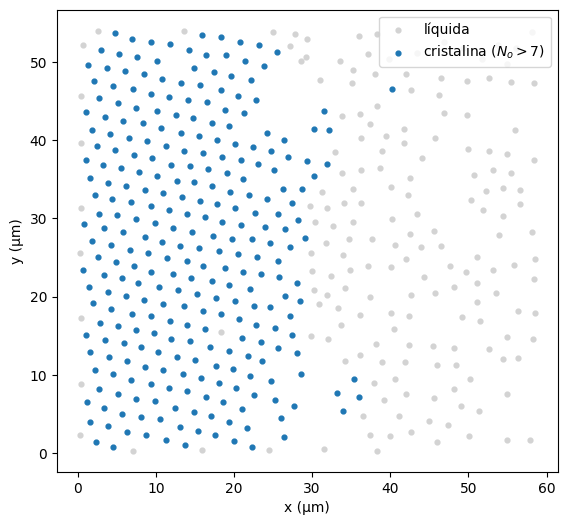

In [4]:
lamina = (X[:, 2] > 8) & (X[:, 2] < 10)
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    *X[lamina & ~cristalina, :2].T,
    s=12, color="lightgray",
    label="líquida"
    )
ax.scatter(
    *X[lamina & cristalina, :2].T,
    s=12, color="tab:blue",
    label="cristalina ($N_o>7$)"
    )
ax.set_xlabel("x (µm)")
ax.set_ylabel("y (µm)")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.show()

## Tarea 1. Grafo de vecinos
Complete `grafo_de_vecinos`. Con unas 4800 partículas conviene un **árbol k-d** (`scipy.spatial.cKDTree`): su método `query_pairs(r)` devuelve los pares $(i, j)$, con $i<j$, a distancia menor que `r`, sin calcular todas las distancias.

*Sugerencia para el asistente de IA:* «¿Cómo construyo con `scipy.spatial.cKDTree` y NetworkX un grafo cuyos nodos sean las filas 0..n-1 de un arreglo X y cuyas aristas unan los pares a menos de r?». Asegúrese de que el grafo incluya también las partículas sin vecinos.

In [5]:
def grafo_de_vecinos(X, rc):
    """Grafo con un nodo por fila de X (nodos 0, ..., n-1) y una arista entre
    las partículas cuyos centros están a menos de rc."""
    # COMPLETAR
    X = np.asarray(X)
    n = len(X)
    tree = cKDTree(X)
    # Pares (i, j) con i < j y distancia <= r, como arreglo (m, 2)
    pares = tree.query_pairs(rc, output_type="ndarray")

    G = nx.Graph()
    G.add_nodes_from(range(n)) # incluye nodos sin vecinos
    G.add_edges_from(pares)    # cada fila es una arista
    return G

In [6]:
# Verificación de la tarea 1
G = grafo_de_vecinos(X, rc)
grado = np.array([G.degree(u) for u in range(len(X))])
assert G.number_of_nodes() == len(X)
coincide = np.mean(grado == c)
assert coincide > 0.95, f"El grado debería coincidir con la columna c en casi todas las partículas ({coincide:.2f})"
dMarkdown(f"**Tarea 1 correcta:** {G.number_of_edges()} aristas; el grado coincide con la coordinación de los autores en el {100*coincide:.0f} % de las partículas")

**Tarea 1 correcta:** 22963 aristas; el grado coincide con la coordinación de los autores en el 98 % de las partículas

### Ver el grafo
Un grafo de 4800 nodos en 3D es ilegible. La función `dibujar` muestra solo una **ventana**: las partículas dentro de una caja, con las aristas entre ellas, proyectadas sobre dos ejes. La usaremos en todo el cuaderno.

In [7]:
def ventana(X, x=(0, 60), y=(0, 60), z=(0, 25)):
    """Índices de las partículas dentro de la caja dada (en µm)."""
    m = ((X[:, 0] >= x[0]) & (X[:, 0] < x[1]) & (X[:, 1] >= y[0]) & (X[:, 1] < y[1])
         & (X[:, 2] >= z[0]) & (X[:, 2] < z[1]))
    return np.where(m)[0]

def dibujar(G, X, nodos, colores="tab:blue", ejes=(0, 1), ax=None, **opciones):
    """Dibuja el subgrafo de los nodos dados, proyectado sobre los ejes elegidos (0 = x, 1 = y, 2 = z)."""
    ax = ax or plt.gca()
    pos = {u: X[u, list(ejes)] for u in nodos}
    nx.draw_networkx_edges(G.subgraph(nodos), pos, ax=ax, edge_color="0.75", width=0.8)
    nx.draw_networkx_nodes(G.subgraph(nodos), pos, nodelist=list(nodos), node_color=colores,
                           node_size=opciones.pop("node_size", 40), ax=ax, **opciones)
    ax.set_xlabel("xyz"[ejes[0]] + " (µm)"); ax.set_ylabel("xyz"[ejes[1]] + " (µm)")
    ax.set_aspect("equal"); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

Una ventana que cruza la interfaz, coloreada por el grado. A la izquierda se ve la red del cristal, con nodos de grado alto; a la derecha, el líquido, más ralo e irregular.

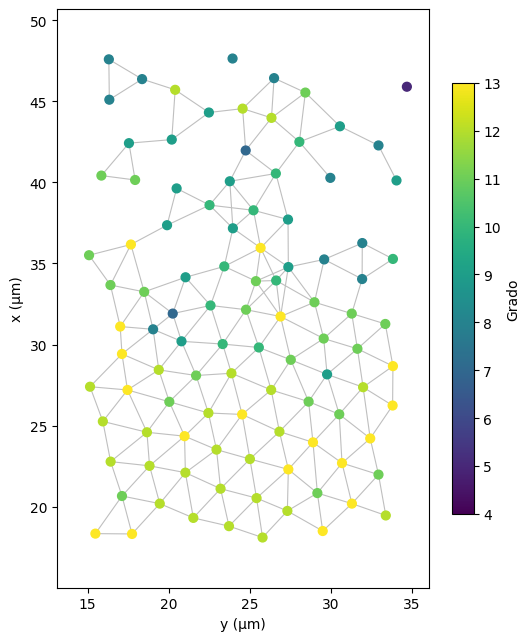

In [8]:
fig, ax = plt.subplots(figsize=(6, 8))
zona_interfaz = ventana(X, x=(18, 48), y=(15, 35), z=(8, 10.5))

# Proyectamos ejes=(1, 0) para graficar 'y' en la horizontal y 'x' en la vertical
dibujar(G, X,
        zona_interfaz,
        colores=grado[zona_interfaz],
        cmap="viridis",
        vmin=4, vmax=13,
        ejes=(1, 0),
        ax=ax
        )

fig.colorbar(ax.collections[-1],
             ax=ax,
             label="Grado",
             shrink=.7)
plt.show()

**Discutan (1 min):** ¿Por qué casi todos los nodos tienen menos aristas dibujadas que su grado? ¿Dónde están los vecinos que faltan? Cuidado: aquí la dirección perpendicular al dibujo es $z$, el eje óptico del microscopio, no la dirección de la gravedad, que es $x$.

Las partículas vecinas que faltan se encuentran fuera de los límites del corte `G.subgraph(nodos)` a lo largo del eje $z$.

In [9]:
nodos_list = list(zona_interfaz)
subG = G.subgraph(nodos_list)

# Encontrar triángulos (clicas de tamaño 3) en el subgrafo
triangulos = [clique for clique in nx.enumerate_all_cliques(subG) if len(clique) == 3]

# Preparar coordenadas para Mesh3D (triángulos) orientando 'x' en la vertical (eje Z de Plotly)
mesh_x, mesh_y, mesh_z = [], [], []
i_idx, j_idx, k_idx = [], [], []
idx_counter = 0

for tri in triangulos:
    # Mapeamos: Plotly_X = Real_Y, Plotly_Y = Real_Z, Plotly_Z = Real_X
    mesh_x.extend([X[tri[0], 1], X[tri[1], 1], X[tri[2], 1]])
    mesh_y.extend([X[tri[0], 2], X[tri[1], 2], X[tri[2], 2]])
    mesh_z.extend([X[tri[0], 0], X[tri[1], 0], X[tri[2], 0]])
    i_idx.append(idx_counter)
    j_idx.append(idx_counter + 1)
    k_idx.append(idx_counter + 2)
    idx_counter += 3

# Trazado para las aristas orientando 'x' en la vertical
edge_x = []
edge_y = []
edge_z = []
for u, v in subG.edges():
    edge_x.extend([X[u, 1], X[v, 1], None])
    edge_y.extend([X[u, 2], X[v, 2], None])
    edge_z.extend([X[u, 0], X[v, 0], None])

trace_edges = go.Scatter3d(
    x=edge_x, y=edge_y, z=edge_z,
    mode='lines',
    line=dict(color='black', width=1.5),
    opacity=0.3,
    hoverinfo='none',
    name='Enlaces (Aristas)',
    showlegend=True
)

# Trazado para los nodos orientando 'x' en la vertical
node_x = X[nodos_list, 1]
node_y = X[nodos_list, 2]
node_z = X[nodos_list, 0]
node_color = grado[nodos_list]
node_text = [f"Nodo: {n}<br>Grado: {g}" for n, g in zip(nodos_list, node_color)]

trace_nodes = go.Scatter3d(
    x=node_x, y=node_y, z=node_z,
    mode='markers',
    marker=dict(
        size=4,
        color=node_color,
        colorscale='turbo',
        colorbar=dict(title='Grado', thickness=20, x=1.15),
        opacity=0.9
    ),
    text=node_text,
    hoverinfo='text',
    name='Partículas (Nodos)',
    showlegend=True
)

# Trazado de triángulos translúcidos (Mesh3d) con 'x' en la vertical
trace_triangles = go.Mesh3d(
    x=mesh_x,
    y=mesh_y,
    z=mesh_z,
    i=i_idx,
    j=j_idx,
    k=k_idx,
    color='cyan',
    opacity=0.30,
    name='Triángulos (Clicas)',
    showlegend=True
)

fig = go.Figure(data=[trace_edges, trace_nodes, trace_triangles])

# Configurar cámara por defecto para visualizar primero el plano x-y físico (Plotly Z vs Plotly X)
# Vista ortogonal desde el eje Y de Plotly (física Z)
camera_config = dict(
    up=dict(x=0, y=0, z=1),
    center=dict(x=0, y=0, z=0),
    eye=dict(x=0, y=-2.0, z=0)  # Mirando de frente al plano Plotly X-Z (físico Y-X)
)

fig.update_layout(
    title="Visualización 3D Interactiva con el eje X orientado verticalmente",
    scene=dict(
        xaxis_title="y (µm)",
        yaxis_title="z (µm)",
        zaxis_title="x (µm, Gravedad/Vertical)",
        camera=camera_config
    ),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255,255,255,0.7)',
        bordercolor='black',
        borderwidth=1
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)
fig.show()

# Parte A — Clasificación de nodos: ¿es cristalina esta partícula?

Los autores clasificaron cada partícula con el orden orientacional ($N_o\ge8$). Suponga que solo conoce esa etiqueta para el **30 % de las partículas**, elegidas al azar, y quiere predecir la del resto a partir del grafo. Note que los nodos no son independientes: una partícula cristalina suele tener vecinos cristalinos, y la agregación de vecindario aprovecha esa correlación.

## Tarea 2. Rasgos de nodo
Complete `rasgos_de_nodo`. Debe devolver una matriz $F$ de forma $(n, 5)$ con estas columnas, en este orden:

| columna | rasgo | definición |
|---|---|---|
| 0 | grado | $d_u=\sum_vA[u,v]$ |
| 1 | agrupamiento | fracción de pares de vecinos de $u$ conectados |
| 2 | agregación de grado, ronda 1 | $\mathbf h^{(1)}=A\,\mathbf d$ |
| 3 | agregación de grado, ronda 2 | $\mathbf h^{(2)}=A\,\mathbf h^{(1)}$ |
| 4 | agrupamiento medio de los vecinos | $(A\,\mathbf c)_u/d_u$ (0 si $d_u=0$) |

Use una matriz de adyacencia **dispersa**, `nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")`: la densa tendría 23 millones de entradas.



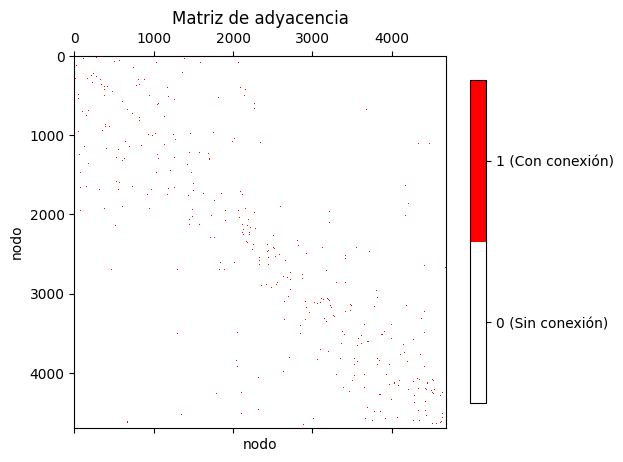

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))

# Obtener la representación densa de la matriz de adyacencia a partir del grafo
A = nx.to_scipy_sparse_array(
    G, nodelist=range(G.number_of_nodes()),
    format="csr").todense()

# Definir mapa de colores binario discreto: blanco (0) y rojo (1)
cmap_wr = ListedColormap(["w", "r"])
cax = ax.matshow(A, cmap=cmap_wr)

# Configurar etiquetas de los ejes y el título del gráfico
ax.set_xlabel("nodo")
ax.set_ylabel("nodo")
ax.set_title("Matriz de adyacencia")

# Añadir barra de colores con marcas (ticks) y etiquetas binarias descriptivas
cbar = fig.colorbar(cax, ax=ax, ticks=[0.25, 0.75], shrink=0.7)
cbar.ax.set_yticklabels(["0 (Sin conexión)", "1 (Con conexión)"])
plt.show()

In [11]:
nombres_nodo = ["grado",
                "agrupamiento",
                "h1", "h2",
                "agrupamiento vecinos"]

def rasgos_de_nodo(G):
    """Matriz (n, 5): grado, agrupamiento, h1 = A d, h2 = A h1 y agrupamiento medio
    de los vecinos, con las filas en el orden de los nodos 0, ..., n-1."""
    n = G.number_of_nodes()
    # Matriz de adyacencia dispersa en formato CSR con los nodos en orden 0, ..., n-1
    A = nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")
    # Columna 0: grado (d_u = sum_v A[u,v])
    d_u = np.array(A.sum(axis=1)).flatten().astype(float)
    # Columna 1: coeficiente de agrupamiento de cada nodo
    c_dict = nx.clustering(G)
    c = np.array([c_dict[u] for u in range(n)], dtype=float)
    # Columna 2: agregación de grado, ronda 1
    h1 = A@d_u
    # Columna 3: agregación de grado, ronda 2
    h2 = A@h1
    # Columna 4: agrupamiento medio de los vecinos
    ac = A@c
    agrup_vecinos = np.divide(
        ac, d_u,
        out=np.zeros(n, dtype=float),
        where=(d_u > 0))
    return np.column_stack([d_u, c, h1, h2, agrup_vecinos])

In [12]:
# Verificación de la tarea 2
F = rasgos_de_nodo(G)
u = 100
assert F.shape == (len(X), 5)
assert np.allclose(F[:, 0], grado), "Revise el grado"
assert np.isclose(F[u, 1], nx.clustering(G, u)), "Revise el agrupamiento"
assert np.isclose(F[u, 2], sum(G.degree(v) for v in G[u])), "h1(u) es la suma de los grados de los vecinos"
assert np.isclose(F[u, 4], np.mean([nx.clustering(G, v) for v in G[u]])), "Revise el agrupamiento de los vecinos"
dMarkdown("**Tarea 2 correcta**")

**Tarea 2 correcta**

In [13]:
F_matriz = rasgos_de_nodo(G)
df_rasgos = pd.DataFrame(F_matriz, columns=nombres_nodo)

# Convertir las columnas de tipo entero (grado, h1, h2) a int
columnas_int_rasgos = ["grado", "h1", "h2"]
df_rasgos[columnas_int_rasgos] = df_rasgos[columnas_int_rasgos].astype(int)

df_rasgos.sample(20)

,grado,agrupamiento,h1,h2,agrupamiento vecinos
937,9,0.388889,92,919,0.361055
3099,12,0.348485,137,1610,0.362963
4623,5,0.600000,41,360,0.429841
955,9,0.305556,89,915,0.345479
149,5,0.100000,26,148,0.181905
591,6,0.266667,27,141,0.239683
2732,10,0.400000,98,1035,0.425606
4447,13,0.358974,159,1882,0.369016
4131,11,0.381818,118,1321,0.405690
1710,11,0.327273,120,1294,0.352204


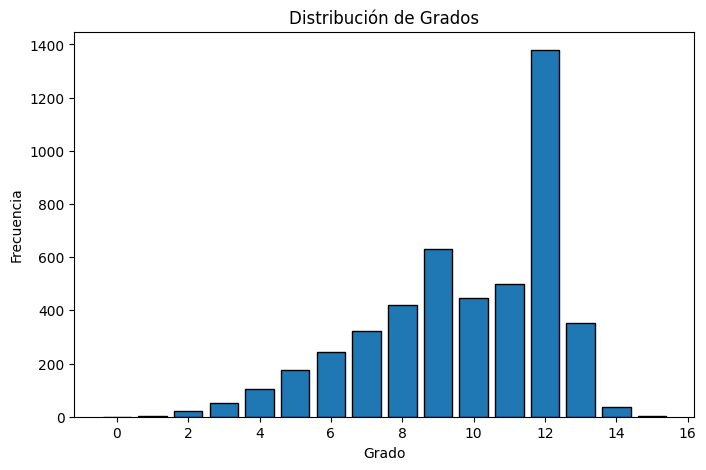

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

# Obtener los grados como enteros a partir de la matriz de adyacencia
grados = np.asarray(A.sum(axis=1)).flatten().astype(int)

# Graficar histograma
pd.Series(grados).plot.hist(
    bins=range(int(grados.max()) + 2),
    edgecolor='black',
    align='left',
    rwidth=0.8,
    ax=ax
)

# Configurar etiquetas y títulos con orientación a objetos
ax.set_xlabel("Grado")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de Grados")
plt.show()

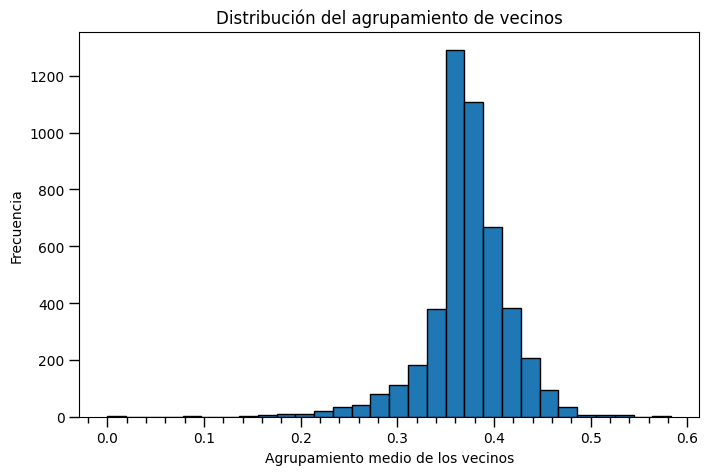

In [15]:
# Crear figura y ejes con estilo orientado a objetos
fig, ax = plt.subplots(figsize=(8, 5))

# Graficar el histograma utilizando el objeto ax
df_rasgos["agrupamiento vecinos"].plot.hist(
    bins=30,
    edgecolor="black",
    ax=ax
)

# Configurar etiquetas y título usando la interfaz orientada a objetos
ax.set_xlabel("Agrupamiento medio de los vecinos")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución del agrupamiento de vecinos")

# Añadir marcas secundarias (subticks) en ambos ejes
ax.xaxis.set_minor_locator(AutoMinorLocator())

# Habilitar ticks menores de manera visual en los cuatro bordes
ax.tick_params(which='both', width=1)
ax.tick_params(which='major', length=7)
ax.tick_params(which='minor', length=4)

plt.show()

Ambas graficas muestran la coexistencia de las fases cristalina y liquida en el coloide a traves del grafo de vecinos.

En la distribucion de grados, el pico dominante en $12$ identifica a las particulas del cristal por su empaquetamiento compacto (FCC/HCP), mientras que la distribucion entre grados $6$ y $10$ corresponde a la fase liquida y a la interfaz.

En el agrupamiento medio de vecinos, el pico estrecho alrededor de $0.38$ refleja la alta cantidad de triangulos y orden local caracteristicos del cristal. La cola izquierda con valores bajos corresponde una menor densidad de vecinos comunes del liquido.

## Tarea 3. Entrenar
Complete `entrenar`: debe devolver `make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))` ajustado a los datos. La misma función servirá en la parte C.



In [16]:
def entrenar(F_train, y_train):
    # Crear un pipeline que estandariza los rasgos (StandardScaler)
    # y luego aplica Regresión Logística
    modelo = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    # Ajustar el modelo utilizando los datos de entrenamiento
    modelo.fit(F_train, y_train)
    return modelo

La celda siguiente separa 30 % de partículas etiquetadas y 70 % por predecir, entrena con distintas combinaciones de rasgos y reporta la exactitud en toda la muestra y en la franja de la interfaz ($27<x<36$ µm). Repite con 10 semillas.

In [17]:
# Definir las etiquetas de nodo (1 para cristalina, 0 para líquida)
y_nodo = cristalina.astype(int)

# Definir la máscara para aislar los nodos ubicados en la zona de la interfaz
franja = (X[:, 0] > 27) & (X[:, 0] < 36)

# Definir las combinaciones de rasgos que evaluaremos secuencialmente
combinaciones = {"solo grado": [0], "grado + agrupamiento": [0, 1], "todos (con agregación)": [0, 1, 2, 3, 4]}

# Calcular las exactitudes de la línea base (clase mayoritaria)
base = max(y_nodo.mean(), 1 - y_nodo.mean())
base_franja = max(y_nodo[franja].mean(), 1 - y_nodo[franja].mean())

# Inicializar la lista de datos de la tabla con la fila de la línea base
datos_tabla = [["línea base",
                f"{base:.3f}",
                f"{base_franja:.3f}"]]

# Iterar sobre cada combinación de rasgos para evaluar su rendimiento
for nombre, cols in combinaciones.items():
    total, interfaz = [], []
    # Realizar validación cruzada de 10 iteraciones con semillas aleatorias
    for semilla in range(10):
        # Dividir los datos en 30% entrenamiento y 70% prueba de forma estratificada
        tr, te = train_test_split(np.arange(len(X)), train_size=0.3, random_state=semilla, stratify=y_nodo)
        # Entrenar el modelo con los rasgos de la combinación actual
        modelo = entrenar(F[tr][:, cols], y_nodo[tr])
        # Registrar la exactitud en toda la muestra de prueba
        total.append(modelo.score(F[te][:, cols], y_nodo[te]))
        # Filtrar el conjunto de prueba para evaluar únicamente la zona de la interfaz
        te_f = te[franja[te]]
        interfaz.append(modelo.score(F[te_f][:, cols], y_nodo[te_f]))

    # Registrar el promedio de los resultados obtenidos para esta combinación
    datos_tabla.append([
        nombre,
        f"{np.mean(total):.3f}",
        f"{np.mean(interfaz):.3f}"
    ])

# Definir los encabezados y mostrar la tabla comparativa de resultados
headers = ["Rasgos", "Toda la muestra (Exactitud)", "Interfaz (Exactitud)"]
dM_table(datos_tabla, headers)

| Rasgos                 |   Toda la muestra (Exactitud) |   Interfaz (Exactitud) |
|:-----------------------|------------------------------:|-----------------------:|
| línea base             |                         0.562 |                  0.531 |
| solo grado             |                         0.772 |                  0.577 |
| grado + agrupamiento   |                         0.811 |                  0.608 |
| todos (con agregación) |                         0.891 |                  0.684 |

### Ver los aciertos y los errores
Con el modelo de todos los rasgos (la última semilla), coloreamos la ventana de la interfaz por la etiqueta de los autores y marcamos con borde rojo las partículas mal clasificadas.

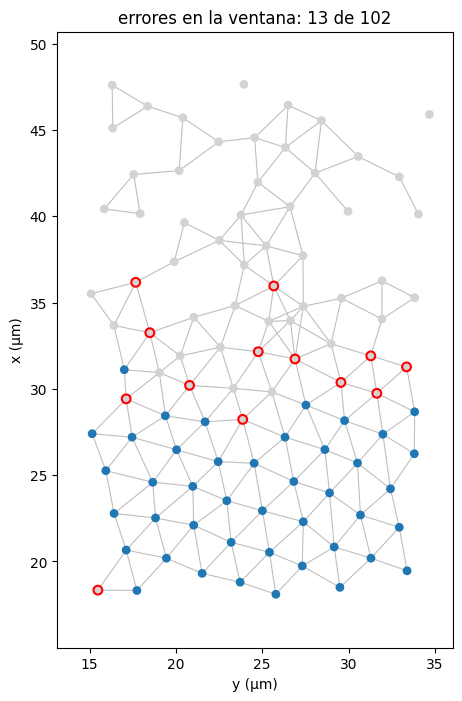

In [18]:
# Obtener las predicciones del modelo para todas las partículas
prediccion = modelo.predict(F)

# Filtrar las partículas correspondientes a la zona de la interfaz
nodos = zona_interfaz
# Identificar cuáles predicciones difieren de las etiquetas reales de los autores
error = prediccion[nodos] != y_nodo[nodos]

fig, ax = plt.subplots(figsize=(6, 8))

# Dibujar el subgrafo coloreando las partículas según su etiqueta real:
# Azul para cristalinas (1) y gris claro para líquidas (0).
# Las partículas con predicción errónea se resaltan con un borde rojo grueso.
# Orientamos el eje 'x' en la vertical utilizando ejes=(1, 0)
dibujar(G, X, nodos,
        colores=np.where(
            y_nodo[nodos] == 1,
            "tab:blue", "lightgray"),
        edgecolors=np.where(error, "red", "none"),
        linewidths=1.5,
        ejes=(1, 0),
        ax=ax
        )

# Añadir título con la cantidad total de errores detectados en la ventana
ax.set_title(f"errores en la ventana: {error.sum()} de {len(nodos)}")
plt.show()

In [19]:
# Filtrar nodos por predicciones correctas e incorrectas
mask_corr = ~error
mask_err  = error

# Separar las clasificaciones correctas en Cristal y Líquido
mask_corr_cristal = mask_corr & (y_nodo[nodos] == 1)
mask_corr_liquido = mask_corr & (y_nodo[nodos] == 0)

# Colores para los errores basados en la etiqueta real
color_err = ["teal" if y == 1 else "aqua" for y in y_nodo[nodos][mask_err]]

# Trazado para las predicciones correctas: Cristal (Plano reorientado: Plotly X = Real Y, Plotly Y = Real Z, Plotly Z = Real X)
trace_corr_cristal = go.Scatter3d(
    x=X[nodos][mask_corr_cristal, 1],
    y=X[nodos][mask_corr_cristal, 2],
    z=X[nodos][mask_corr_cristal, 0],
    mode='markers',
    marker=dict(size=5, color="teal", opacity=0.6),
    name="Correcto: Cristal",
    text=[f"Nodo: {n}<br>Real: Cristal" for n in nodos[mask_corr_cristal]],
    hoverinfo='text'
)

# Trazado para las predicciones correctas: Líquido
trace_corr_liquido = go.Scatter3d(
    x=X[nodos][mask_corr_liquido, 1],
    y=X[nodos][mask_corr_liquido, 2],
    z=X[nodos][mask_corr_liquido, 0],
    mode='markers',
    marker=dict(size=5, color="aqua", opacity=0.6),
    name="Correcto: Líquido",
    text=[f"Nodo: {n}<br>Real: Líquido" for n in nodos[mask_corr_liquido]],
    hoverinfo='text'
)

# Trazado para los errores (marcados con bordes rojos)
trace_err = go.Scatter3d(
    x=X[nodos][mask_err, 1],
    y=X[nodos][mask_err, 2],
    z=X[nodos][mask_err, 0],
    mode='markers',
    marker=dict(
        size=8,
        color=color_err,
        line=dict(color='red', width=5),
        opacity=1.0
    ),
    name="Errores (Borde Rojo)",
    text=[f"Nodo: {n}<br>Real: {'Cristal' if y==1 else 'Líquido'}<br>¡Predicción incorrecta!"
          for n, y in zip(nodos[mask_err], y_nodo[nodos][mask_err])],
    hoverinfo='text'
)

fig = go.Figure(data=[trace_corr_cristal, trace_corr_liquido, trace_err])
fig.update_layout(
    title=f"Visualización 3D de los Errores de Clasificación con el eje X orientado verticalmente ({error.sum()} errores)",
    scene=dict(
        xaxis_title="y (µm)",
        yaxis_title="z (µm)",
        zaxis_title="x (µm, Gravedad/Vertical)"
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    legend=dict(x=0.01, y=0.99, itemsizing='constant')
)
fig.show()

**Discutan:** ¿dónde se concentran los errores? ¿Por qué la agregación mejora la exactitud? Piense en el campo receptivo: con $h^{(2)}$, cada partícula "ve" a sus vecinos a dos saltos. ¿Por qué la exactitud cae tanto en la interfaz?

* **¿Dónde se concentran los errores?:** En la interfaz cristal-líquido, donde la estructura no es uniforme y sufre constantes fluctuaciones locales.

* **¿Por qué mejora la agregación?:** Filtra el ruido térmico local al promediar el entorno con vecinos de hasta 2 saltos ($h^{(2)}$), aprovechando que partículas del mismo estado suelen agruparse.

* **¿Por qué cae la exactitud en la interfaz?:** Porque $h^{(2)}$ mezcla vecinos de ambas fases (suaviza la frontera) y el grafo solo mide cantidad de vecinos (densidad radial), ignorando los ángulos de orientación donde ocurre el corte real.

Las esferas duras se cristalizan porque ordenarse optimiza el espacio y deja más volumen libre alrededor de cada partícula para vibrar y moverse sin chocar.

Esta ganancia de libertad de movimiento local da lugar a más microestados accesibles (mayor multiplicidad), y aumenta la entropía total del sistema, impulsando la cristalización sin necesidad de fuerzas atractivas.

En la interfaz ocurre lo opuesto, las esferas no encajan bien en ninguna de las dos fases, pierden espacio libre y sufren una penalización entrópica que genera tensión superficial.

# Parte B — Predicción de relaciones: ¿quiénes serán vecinos?

En un líquido las partículas cambian de vecinos (la "jaula" que forman sus vecinos se reorganiza), y en un cristal casi no. Los autores midieron esta diferencia con el desplazamiento de las partículas: la movilidad sube del cristal al líquido a lo largo de unos $2.4\,d$, y en el líquido la difusión es unas 50 veces más lenta que en una suspensión diluida, porque la muestra es muy densa. Con el grafo en el instante $t$, ¿podemos predecir qué parejas de partículas serán vecinas en $t+\Delta t$, con $\Delta t=100$ s (4 instantes)?

**Candidatos.** Dos partículas a dos saltos en el grafo, es decir, no vecinas pero con al menos un vecino común, son las candidatas naturales a volverse vecinas. Para cada candidata usaremos como puntaje el número de vecinos comunes, que es $A^2[u,v]$ (sesión 1).

**Etiqueta.** La pareja es positiva si en $t+\Delta t$ sus centros están a menos de $r_c$. Como las partículas se identifican por su `ID`, la celda siguiente (ya escrita) construye las aristas del instante futuro expresadas con los índices del instante 0.

In [20]:
# Instantes; 4 x 25 s = 100 s
dt = 4
X_f, _, _, ID_f = instante(dt)
# ID -> índice del nodo en el instante 0
indice = {i: j for j, i in enumerate(ID)}
ids_f = set(ID_f)
# Partículas que siguen en la imagen en t + dt
presentes = np.array([i in ids_f for i in ID])
futuras = set()
for a, b in cKDTree(X_f).query_pairs(rc):
    if ID_f[a] in indice and ID_f[b] in indice:
        u, v = sorted((indice[ID_f[a]], indice[ID_f[b]]))
        futuras.add((u, v))
dMarkdown(f"${len(futuras)}$ aristas en $t+\\mathrm{{d}}t$ entre partículas presentes en $t = 0$")

$18476$ aristas en $t+\mathrm{d}t$ entre partículas presentes en $t = 0$

## Tarea 4. Parejas a dos saltos y sus vecinos comunes
Complete `pares_a_dos_saltos`. Debe devolver un arreglo `P` de forma $(m, 2)$ con todas las parejas $u<v$ **no vecinas** que tienen al menos un vecino común, y un arreglo `vc` con el número de vecinos comunes de cada pareja. Una forma eficiente: las entradas no nulas de $A^2$ fuera de la diagonal son exactamente las parejas con vecinos comunes, y su valor es cuántos; quedan por quitar las parejas que ya son vecinas.



In [21]:
def pares_a_dos_saltos(G):
    """Parejas u < v no vecinas con al menos un vecino común (arreglo m x 2)
    y el número de vecinos comunes de cada una (arreglo de longitud m)."""
    n = G.number_of_nodes()
    # Obtener la matriz de adyacencia dispersa A
    A = nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")
    # Calcular A^2 (el producto matricial nos da los vecinos comunes en las posiciones (u, v))
    A2 = A@A
    # Extraer la parte triangular superior estricta para garantizar u < v y evitar autoconexiones (u == v)
    A2_triu = triu(A2, k=1, format="csr")
    # Obtener los índices fila (u) y columna (v) de los elementos que son mayores a cero
    u_idx, v_idx    = A2_triu.nonzero()
    vecinos_comunes = A2_triu.data
    # Filtrar para quedarnos únicamente con las parejas que NO son vecinas en el grafo original
    no_vecinos = []
    vc_filtrados = []

    for i in range(len(u_idx)):
        u = u_idx[i]
        v = v_idx[i]
        if not G.has_edge(u, v):
            no_vecinos.append([u, v])
            vc_filtrados.append(vecinos_comunes[i])

    return np.array(no_vecinos), np.array(vc_filtrados)

In [22]:
# Verificación de la tarea 4
P, vc = pares_a_dos_saltos(G)
assert P.shape[1] == 2 and len(P) == len(vc) and np.all(P[:, 0] < P[:, 1])
assert not any(G.has_edge(u, v) for u, v in P[:2000]), "Las parejas no pueden ser ya vecinas"
for k in [0, 500, 5000]:
    u, v = P[k]
    assert vc[k] == len(set(G[u]) & set(G[v])), "Revise el conteo de vecinos comunes"
dMarkdown(f"**Tarea 4 correcta:** {len(P)} parejas a dos saltos")

**Tarea 4 correcta:** 74637 parejas a dos saltos

### ¿Predicen los vecinos comunes los vecinos futuros?
Nos quedamos con las parejas cuyas dos partículas siguen en la imagen, calculamos la etiqueta y medimos el AUC del puntaje de vecinos comunes. Como comparación usamos la **distancia** actual entre las dos partículas (menor distancia, mayor puntaje), que es información geométrica y no del grafo.

In [23]:
# Filtrar para quedarnos solo con las parejas donde ambas partículas siguen presentes
validas = presentes[P[:, 0]] & presentes[P[:, 1]]
P_v, vc_v = P[validas], vc[validas]

# Crear las etiquetas: 1 si la pareja se vuelve vecina en el futuro, 0 si no
y_rel = np.array([(u, v) in futuras for u, v in P_v]).astype(int)

# Calcular la distancia euclidiana actual entre las partículas de cada pareja
distancia = np.linalg.norm(X[P_v[:, 0]] - X[P_v[:, 1]], axis=1)

# Asignar una zona (cristal, líquido o interfaz) según la posición x de la primera partícula
zona = np.where(X[P_v[:, 0], 0] < 25, "cristal", np.where(X[P_v[:, 0], 0] > 40, "líquido", "interfaz"))

# Preparar los encabezados y los datos para la tabla Markdown
headers = ["Zona", "Parejas", "Positivos", "AUC vecinos comunes", "AUC distancia"]
datos_tabla = []

# Calcular las métricas para cada zona y para toda la muestra conjunta
for z in ["cristal", "interfaz", "líquido", "todas"]:
    m = np.ones(len(y_rel), bool) if z == "todas" else zona == z
    datos_tabla.append([
        z,
        f"{m.sum()}",
        f"{y_rel[m].mean():.3f}",
        f"{roc_auc_score(y_rel[m], vc_v[m]):.3f}",
        f"{roc_auc_score(y_rel[m], -distancia[m]):.3f}"
    ])

# Mostrar la tabla formateada usando la función personalizada
dM_table(datos_tabla, headers)

| Zona     |   Parejas |   Positivos |   AUC vecinos comunes |   AUC distancia |
|:---------|----------:|------------:|----------------------:|----------------:|
| cristal  |     39036 |       0.008 |                 0.898 |           0.963 |
| interfaz |     18069 |       0.04  |                 0.752 |           0.873 |
| líquido  |      3225 |       0.105 |                 0.643 |           0.784 |
| todas    |     60330 |       0.023 |                 0.719 |           0.847 |

### Ver una jaula que se reorganiza
Elegimos una partícula del líquido y dibujamos su vecindario a dos saltos en $t=0$ (aristas grises). Encima marcamos en verde las aristas que aparecen en $t+\Delta t$ y en rojo las que desaparecen. La proyección es sobre $(x, y)$, así que dos partículas pueden parecer cercanas aunque estén separadas en $z$.

### Visualización de la Reorganización de la Jaula
Analizando el vecindario de la partícula central **322** en el líquido:

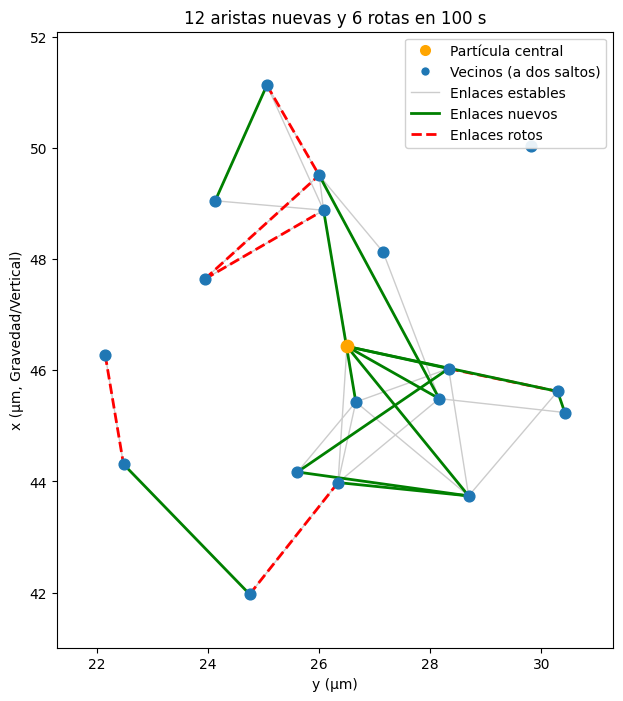

In [24]:
# Identificar la partícula central en una ventana específica del líquido
centro = ventana(X, x=(44, 48), y=(25, 29), z=(8, 12))[0]

# Obtener el vecindario a dos saltos en t=0 (nodos a distancia <= 2 del centro)
vecindario = list(nx.single_source_shortest_path_length(G, centro, cutoff=2))
vecindario = [u for u in vecindario if presentes[u]]

# Crear el subgrafo inducido por el vecindario
H = G.subgraph(vecindario)

# Identificar nuevas aristas que aparecen en t + dt
nuevas = [(u, v) for u in vecindario for v in vecindario if u < v and (u, v) in futuras and not G.has_edge(u, v)]

# Identificar aristas existentes que se rompen en t + dt
rotas = [(u, v) for u, v in H.edges() if tuple(sorted((u, v))) not in futuras]

# Imprimir una descripción elegante de la figura usando dMarkdown
dMarkdown(f"### Visualización de la Reorganización de la Jaula\nAnalizando el vecindario de la partícula central **{centro}** en el líquido:")

# Configurar y dibujar el grafo con x vertical e y horizontal
fig, ax = plt.subplots(figsize=(8, 8))
pos = {u: X[u, [1, 0]] for u in vecindario}  # Ejes: horizontal = Y (índice 1), vertical = X (índice 0)

# Dibujar las aristas del grafo original en gris claro
e_originales = nx.draw_networkx_edges(H, pos, ax=ax, edge_color="0.8", width=1)

# Dibujar las aristas rotas con líneas discontinuas rojas
e_rotas = nx.draw_networkx_edges(H, pos, edgelist=rotas, edge_color="red", width=2, style="dashed", ax=ax)

# Dibujar las nuevas aristas en verde
e_nuevas = nx.draw_networkx_edges(nx.Graph(nuevas), pos, edge_color="green", width=2, ax=ax)

# Dibujar por separado el nodo central (naranja) y los vecinos (azul) para poder etiquetarlos en la leyenda
nodos_vecinos = [u for u in vecindario if u != centro]
n_centro = nx.draw_networkx_nodes(H, pos, nodelist=[centro], node_size=80, node_color="orange", ax=ax)
n_vecinos = nx.draw_networkx_nodes(H, pos, nodelist=nodos_vecinos, node_size=60, node_color="tab:blue", ax=ax)

# Configurar títulos, ejes y aspecto de la gráfica
ax.set_title(f"{len(nuevas)} aristas nuevas y {len(rotas)} rotas en {25*dt} s")
ax.set_aspect("equal")
ax.set_xlabel("y (µm)")
ax.set_ylabel("x (µm, Gravedad/Vertical)")
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

# Crear la leyenda de manera manual usando los objetos de dibujo creados
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Partícula central', markerfacecolor='orange', markersize=9),
    Line2D([0], [0], marker='o', color='w', label='Vecinos (a dos saltos)', markerfacecolor='tab:blue', markersize=7),
    Line2D([0], [0], color='0.8', lw=1, label='Enlaces estables'),
    Line2D([0], [0], color='green', lw=2, label='Enlaces nuevos'),
    Line2D([0], [0], color='red', lw=2, linestyle='--', label='Enlaces rotos')
]

ax.legend(handles=legend_elements, loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

plt.show()

**Discutan:** ¿en qué zona se forman más enlaces nuevos y por qué? ¿Por qué el AUC no se ve afectado por que los positivos sean tan pocos? La distancia predice mejor que los vecinos comunes: ¿qué dice eso sobre la información que el grafo descarta?

* **¿En qué zona se forman más enlaces nuevos y por qué?:** El líquido lidera en proporción debido a la alta movilidad de sus partículas, mientras que el cristal las inmoviliza en una red rígida y la interfaz se encuentra con un comportamiento intermedio.


* **¿Por qué el AUC no se ve afectado por que los positivos sean tan pocos?:** Al evaluar únicamente el ordenamiento relativo de los puntajes, es totalmente inmune al desbalance entre clases.


* **¿Qué dice eso sobre la información que el grafo descarta?:** El grafo sin pesos descarta por completo las direcciones espaciales, tratando de forma idéntica enlaces que ocurren en diferentes orientaciones angulares y reduciendo toda la geometría tridimensional a una simple cuenta de vecinos y caminos discretos.

## Tarea 5 (opcional). Enlaces que se rompen
La pregunta inversa: de las aristas en $t=0$ entre partículas presentes en $t+\Delta t$, ¿cuáles se romperán? Calcule la fracción de aristas rotas en el cristal y en el líquido, y el AUC de dos puntajes: menos vecinos comunes (un enlace con muchos vecinos comunes está "protegido" por su entorno) y la longitud del enlace.

In [25]:
dMarkdown("Iniciando filtrado de aristas presentes...")
# Filtrar aristas de G (en t=0) cuyos dos extremos siguen presentes en t+Δt
%time aristas_presentes = [(min(u, v), max(u, v)) for u, v in tqdm(G.edges(), desc="Filtrando aristas") if presentes[u] and presentes[v]]
dMarkdown("Filtrado de aristas presentes: **hecho**")

dMarkdown("Iniciando evaluación de aristas rotas...")
# Etiqueta "se rompe":
# 1 si el enlace ya NO existe en el conjunto 'futuras' (en t+Δt), 0 si se mantiene.
%time y_rompe = np.array([int((u, v) not in futuras) for u, v in tqdm(aristas_presentes, desc="Evaluando aristas rotas")])
dMarkdown("Evaluación de aristas rotas: **hecho**")

dMarkdown("Iniciando cálculo de vecinos comunes ($A_2$)... (se demora)")
# Puntaje 1: Menos vecinos comunes en t=0
%time A2 = A@A  # cuenta los vecinos comunes en G
dMarkdown("Cálculo de $A_2$: **hecho**")

dMarkdown("Iniciando evaluación de vecinos comunes por arista...")
%time vecinos_comunes = np.array([A2[u, v] for u, v in tqdm(aristas_presentes, desc="Evaluando vecinos comunes")])
puntaje_menos_vc = -vecinos_comunes
dMarkdown("Cálculo del puntaje de vecinos comunes: **hecho**")

dMarkdown("Iniciando cálculo de longitud de enlaces...")
# Puntaje 2: Longitud del enlace en t=0
%time longitud_enlace = np.array([np.linalg.norm(X[u] - X[v]) for u, v in tqdm(aristas_presentes, desc="Evaluando longitud de enlace")])
dMarkdown("Cálculo de longitud de enlaces: **hecho**")

dMarkdown("Iniciando evaluación de fracciones en cristal y líquido...")
# Fracción de aristas rotas en el cristal y en el líquido
%time en_cristal = np.array([bool(cristalina[u] and cristalina[v]) for u, v in tqdm(aristas_presentes, desc="Evaluando en cristal")], dtype=bool)

%time en_liquido = np.array([bool(not cristalina[u] and not cristalina[v]) for u, v in tqdm(aristas_presentes, desc="Evaluando en líquido")], dtype=bool)

dMarkdown("Iniciando cálculo de fracciones de rotura...")
%time frac_rotas_total   = y_rompe.mean()
%time frac_rotas_cristal = y_rompe[en_cristal].mean()
%time frac_rotas_liquido = y_rompe[en_liquido].mean()
dMarkdown("Cálculo de fracciones de rotura: **hecho**")

dMarkdown("Iniciando cálculo de métricas AUC...")
# Cálculo de los dos AUC
%time auc_menos_vc = roc_auc_score(y_rompe, puntaje_menos_vc)
%time auc_longitud = roc_auc_score(y_rompe, longitud_enlace)
dMarkdown("Cálculo de métricas AUC: **hecho**")

dMarkdown(f"""
* **Total de aristas evaluadas ($t=0$ presentes en $t+\\Delta t$):** {len(aristas_presentes)}
* **Fracción global de aristas rotas:** {frac_rotas_total:.3f}
* **Fracción de aristas rotas en el cristal:** {frac_rotas_cristal:.3f}
* **Fracción de aristas rotas en el líquido:** {frac_rotas_liquido:.3f}
* **AUC (menos vecinos comunes):** {auc_menos_vc:.3f}
* **AUC (longitud del enlace):** {auc_longitud:.3f}
""")

Iniciando filtrado de aristas presentes...

Filtrando aristas:   0%|          | 0/22963 [00:00<?, ?it/s]

CPU times: user 54.8 ms, sys: 1.72 ms, total: 56.5 ms
Wall time: 62.5 ms


Filtrado de aristas presentes: **hecho**

Iniciando evaluación de aristas rotas...

Evaluando aristas rotas:   0%|          | 0/18411 [00:00<?, ?it/s]

... (21 outputs left out)

Iniciando cálculo de métricas AUC...

CPU times: user 10.9 ms, sys: 994 µs, total: 11.9 ms
Wall time: 18.5 ms
CPU times: user 12.8 ms, sys: 0 ns, total: 12.8 ms
Wall time: 14.4 ms


Cálculo de métricas AUC: **hecho**


* **Total de aristas evaluadas ($t=0$ presentes en $t+\Delta t$):** 18411
* **Fracción global de aristas rotas:** 0.075
* **Fracción de aristas rotas en el cristal:** 0.027
* **Fracción de aristas rotas en el líquido:** 0.285
* **AUC (menos vecinos comunes):** 0.661
* **AUC (longitud del enlace):** 0.771


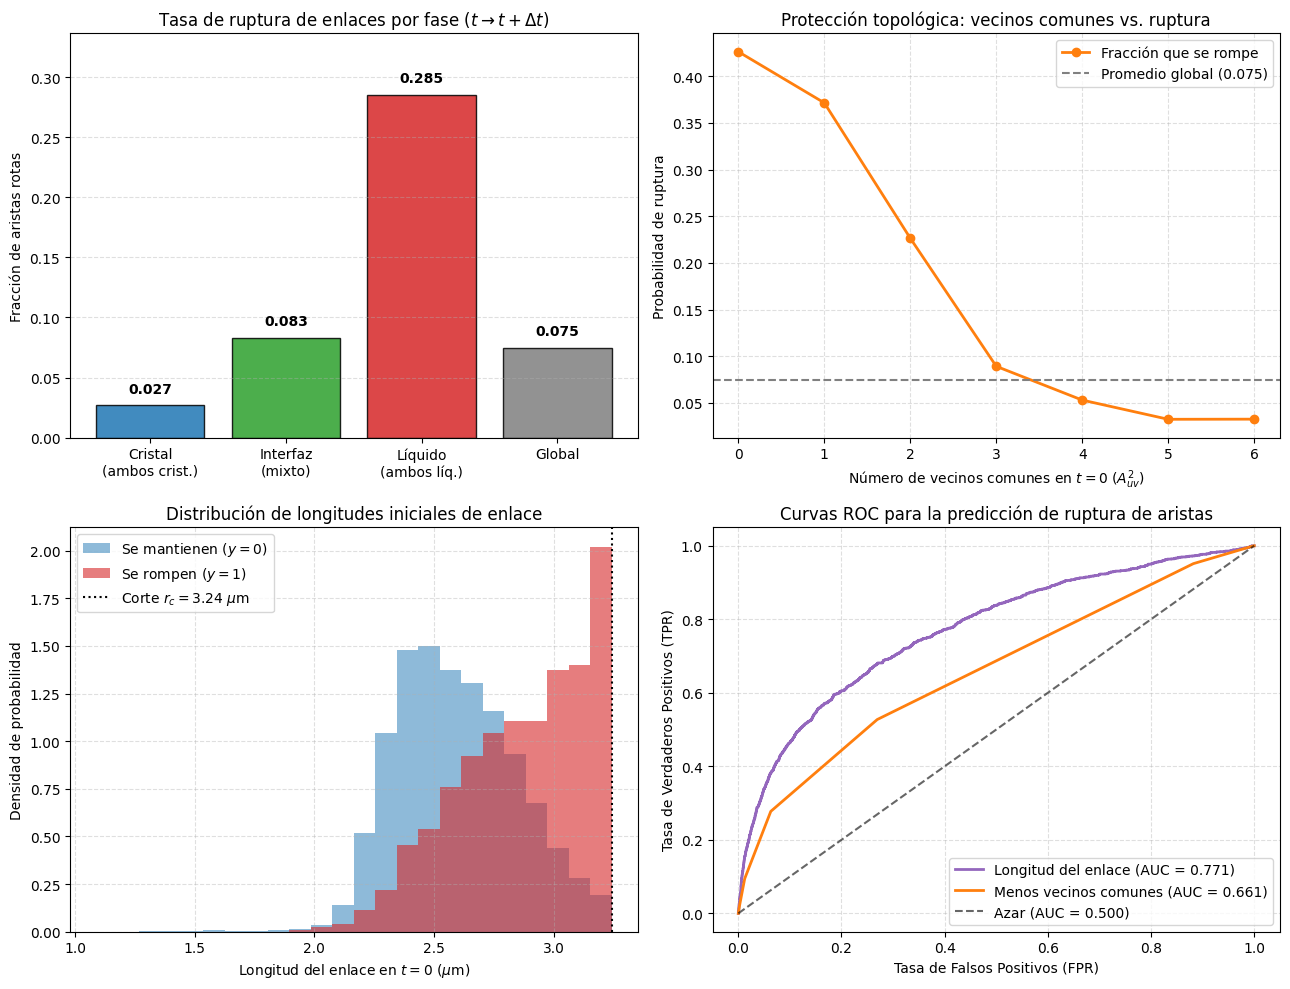

In [26]:
# Máscara para aristas en la interfaz (un extremo cristalino y otro líquido)
en_interfaz = ~(en_cristal | en_liquido)
frac_rotas_interfaz = y_rompe[en_interfaz].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# --- Panel 1: Fracción de aristas rotas por región ---
ax = axes[0, 0]
fases = ["Cristal\n(ambos crist.)", "Interfaz\n(mixto)", "Líquido\n(ambos líq.)", "Global"]
fracciones = [frac_rotas_cristal, frac_rotas_interfaz, frac_rotas_liquido, frac_rotas_total]
colores = ["#1f77b4", "#2ca02c", "#d62728", "#7f7f7f"]

barras = ax.bar(fases, fracciones, color=colores, edgecolor="black", alpha=0.85)
ax.set_ylabel("Fracción de aristas rotas")
ax.set_title("Tasa de ruptura de enlaces por fase ($t \\to t + \\Delta t$)")
ax.set_ylim(0, max(fracciones)*1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for barra, val in zip(barras, fracciones):
    ax.text(
        barra.get_x() + barra.get_width()/2,
        val + 0.008,
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# --- Panel 2: Tasa de ruptura vs. Vecinos comunes en t=0 ---
ax = axes[0, 1]
vc_unicos = np.unique(vecinos_comunes)
tasa_por_vc = [y_rompe[vecinos_comunes == k].mean() for k in vc_unicos]
conteo_por_vc = [np.sum(vecinos_comunes == k) for k in vc_unicos]

# Filtrar valores con suficiente estadística (al menos 20 aristas)
mask_vc = np.array(conteo_por_vc) >= 20
ax.plot(
    vc_unicos[mask_vc],
    np.array(tasa_por_vc)[mask_vc],
    marker="o",
    linewidth=2,
    color="#ff7f0e",
    label="Fracción que se rompe",
)
ax.axhline(frac_rotas_total, color="gray", linestyle="--", label=f"Promedio global ({frac_rotas_total:.3f})")
ax.set_xlabel("Número de vecinos comunes en $t=0$ ($A^2_{uv}$)")
ax.set_ylabel("Probabilidad de ruptura")
ax.set_title("Protección topológica: vecinos comunes vs. ruptura")
ax.set_xticks(vc_unicos[mask_vc])
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

# --- Panel 3: Distribución de longitud de enlace y probabilidad de ruptura ---
ax = axes[1, 0]
bins = np.linspace(longitud_enlace.min(), rc, 25)
ax.hist(
    longitud_enlace[y_rompe == 0],
    bins=bins,
    density=True,
    alpha=0.5,
    color="#1f77b4",
    label="Se mantienen ($y=0$)",
)
ax.hist(
    longitud_enlace[y_rompe == 1],
    bins=bins,
    density=True,
    alpha=0.6,
    color="#d62728",
    label="Se rompen ($y=1$)",
)
ax.axvline(rc, color="black", linestyle=":", linewidth=1.5, label=f"Corte $r_c = {rc:.2f}\\ \\mu$m")
ax.set_xlabel("Longitud del enlace en $t=0$ ($\\mu$m)")
ax.set_ylabel("Densidad de probabilidad")
ax.set_title("Distribución de longitudes iniciales de enlace")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

# --- Panel 4: Curvas ROC de ambos puntajes ---
ax = axes[1, 1]
fpr_vc, tpr_vc, _ = roc_curve(y_rompe, puntaje_menos_vc)
fpr_lon, tpr_lon, _ = roc_curve(y_rompe, longitud_enlace)

ax.plot(
    fpr_lon,
    tpr_lon,
    linewidth=2,
    color="#9467bd",
    label=f"Longitud del enlace (AUC = {auc_longitud:.3f})",
)
ax.plot(
    fpr_vc,
    tpr_vc,
    linewidth=2,
    color="#ff7f0e",
    label=f"Menos vecinos comunes (AUC = {auc_menos_vc:.3f})",
)
ax.plot([0, 1], [0, 1], color="black", linestyle="--", alpha=0.6, label="Azar (AUC = 0.500)")
ax.set_xlabel("Tasa de Falsos Positivos (FPR)")
ax.set_ylabel("Tasa de Verdaderos Positivos (TPR)")
ax.set_title("Curvas ROC para la predicción de ruptura de aristas")
ax.legend(loc="lower right")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

* **Cristalización arriba y gradiente de gravedad:** La gravedad genera un gradiente de concentración por la diferencia de densidad con el solvente (acumulando normalmente el cristal abajo). Sin embargo, en el experimento de Hernández-Guzmán y Weeks, el solvente (con exceso de decalina) es ligeramente **más denso que las partículas** ($\Delta \rho < 5 \times 10^{-4}\text{ g/mL}$), lo que permite que las esferas floten y cristalicen hacia arriba; asimismo, en muestras muy viscosas (Pusey y van Megen, muestras 8-10), donde el fondo queda atrapado como vidrio amorfo, la cristalización heterogénea se inicia arriba desde el **menisco**.


* **Interacciones coulombianas:** En suspensiones con partículas eléctricamente cargadas, la **repulsión coulombiana** genera orden cristalino de largo alcance incluso con separaciones mucho mayores al diámetro de la partícula. En la muestra de PMMA estudiada, esta ligera carga eléctrica desplaza las fronteras de coexistencia hacia fracciones de volumen menores ($\phi_{\text{freeze}} = 0.43$ y $\phi_{\text{melt}} = 0.49$) respecto a las esferas duras ideales ($0.494$ y $0.545$).

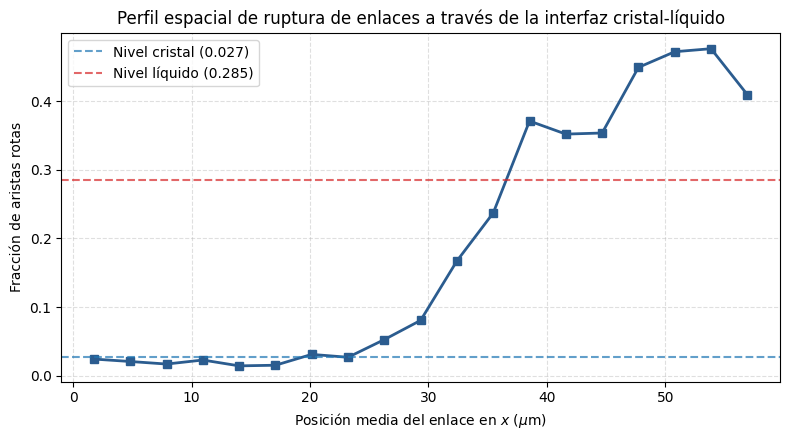

In [27]:
# Coordenada x media de cada arista evaluada en t=0
x_medio_arista = np.array([0.5*(X[u, 0] + X[v, 0]) for u, v in aristas_presentes])

bins_x = np.linspace(x_medio_arista.min(), x_medio_arista.max(), 20)
indices_bin = np.digitize(x_medio_arista, bins_x)
centros_x = 0.5*(bins_x[:-1] + bins_x[1:])

frac_x = [
    y_rompe[indices_bin == i].mean() if np.any(indices_bin == i) else np.nan
    for i in range(1, len(bins_x))
]

plt.figure(figsize=(8, 4.5))
plt.plot(centros_x, frac_x, marker="s", color="#2b5c8f", linewidth=2)
plt.axhline(frac_rotas_cristal, color="#1f77b4", linestyle="--", alpha=0.7, label=f"Nivel cristal ({frac_rotas_cristal:.3f})")
plt.axhline(frac_rotas_liquido, color="#d62728", linestyle="--", alpha=0.7, label=f"Nivel líquido ({frac_rotas_liquido:.3f})")
plt.xlabel("Posición media del enlace en $x$ ($\\mu$m)")
plt.ylabel("Fracción de aristas rotas")
plt.title("Perfil espacial de ruptura de enlaces a través de la interfaz cristal-líquido")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Parte C — Clasificación de grafos: ¿dónde termina el cristal?

Ahora cada capa de la muestra, de un diámetro de ancho a lo largo de $x$, en cada instante, es un grafo que hay que clasificar como cristal o líquido: 23 capas por 150 instantes dan 3450 grafos. Es la versión experimental de las fases del modelo de Ising, con la fracción de volumen en lugar de la temperatura.

Para cada capa calculamos cinco rasgos. Los tres últimos imitan los dominios del Ising: llamamos densa a una partícula con al menos 10 vecinos y estudiamos los grupos conectados que forman las partículas densas de la capa.

| rasgo | definición |
|---|---|
| grado medio | promedio de $d_u$ en la capa |
| agrupamiento medio | promedio de $c_u$ en la capa |
| fracción densa | fracción de partículas de la capa con $d_u\ge10$ |
| grupo mayor | tamaño del mayor grupo conectado de partículas densas, dividido por el número de partículas de la capa |
| número de grupos | número de grupos conectados de partículas densas = multiplicidad del autovalor 0 de su Laplaciano |

## Tarea 6. Rasgos de una capa
Complete `rasgos_de_capa`. Recibe el grafo del instante, el grado y el agrupamiento de cada nodo (ya calculados) y los nodos de la capa.



In [28]:
nombres_capa = ["grado medio", "agrupamiento", "fracción densa", "grupo mayor", "número de grupos"]

def rasgos_de_capa(G, grado, agrupamiento, nodos, umbral=10):
    """Cinco rasgos de la capa formada por `nodos` (arreglo de índices): grado medio,
    agrupamiento medio, fracción de partículas densas (grado >= umbral), tamaño relativo
    del mayor grupo conectado de partículas densas y número de esos grupos."""
    grado_medio = grado[nodos].mean()
    agrup_medio = agrupamiento[nodos].mean()

    densos = nodos[grado[nodos] >= umbral]
    fraccion_densa = len(densos)/len(nodos)

    grupos = list(nx.connected_components(G.subgraph(densos)))
    grupo_mayor = max((len(g) for g in grupos), default=0)/len(nodos)
    num_grupos = len(grupos)

    return [grado_medio, agrup_medio, fraccion_densa, grupo_mayor, num_grupos]

In [29]:
# Verificación de la tarea 6
# Diámetro original de la partícula en µm

# Capas de un diámetro de ancho
bordes = np.arange(0, 58.6, diametro)
centros = (bordes[:-1] + bordes[1:])/2
capa = np.digitize(X[:, 0], bordes) - 1
# Una capa del lado líquido
nodos = np.where(capa == 18)[0]
r = rasgos_de_capa(G, grado, F[:, 1], nodos)
assert len(r) == 5 and np.isclose(r[0], grado[nodos].mean()) and np.isclose(r[1], F[nodos, 1].mean())
densos = [u for u in nodos if grado[u] >= 10]
ceros = np.sum(np.abs(np.linalg.eigvalsh(nx.laplacian_matrix(G.subgraph(densos)).toarray())) < 1e-8)
assert r[4] == ceros, "El número de grupos debe ser la multiplicidad del autovalor 0 del Laplaciano"

dMarkdown(f"**Tarea 6 correcta:**")
datos_tabla_capa = [[n, f"{float(v):.3f}"] for n, v in zip(nombres_capa, r)]
headers_capa = ["Métrica de Capa", "Valor"]
dM_table(datos_tabla_capa, headers_capa)

**Tarea 6 correcta:**

| Métrica de Capa   |   Valor |
|:------------------|--------:|
| grado medio       |   8.163 |
| agrupamiento      |   0.358 |
| fracción densa    |   0.262 |
| grupo mayor       |   0.064 |
| número de grupos  |  14     |

### Ver dos capas
Una capa del cristal y una del líquido, vistas de frente (plano $y$-$z$). Las partículas densas están coloreadas según el grupo conectado al que pertenecen; las demás, en gris. En el cristal casi todas forman un único grupo; en el líquido aparecen muchos grupos pequeños.

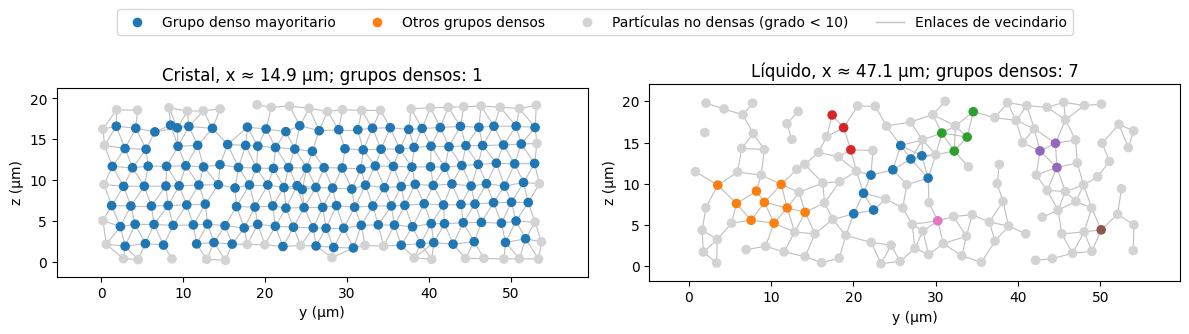

In [30]:
# Visualización de dos capas (Cristal y Líquido) en el plano Y-Z con sus grupos densos
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

for a, j, titulo in [(ax[0], 6, "cristal"), (ax[1], 20, "líquido")]:
    # Identificar partículas que pertenecen a la capa j
    nodos = np.where(capa == j)[0]

    # Encontrar componentes conectados formados únicamente por partículas densas (grado >= 10)
    grupos = sorted(nx.connected_components(G.subgraph([u for u in nodos if grado[u] >= 10])), key=len, reverse=True)

    # Crear un diccionario para mapear cada nodo a su respectivo identificador de grupo
    etiqueta = {u: g for g, grupo in enumerate(grupos) for u in grupo}

    # Asignar un color distintivo según el grupo, dejando en gris claro las partículas no densas
    colores = [plt.cm.tab10(etiqueta[u] % 10) if u in etiqueta else "lightgray" for u in nodos]

    # Dibujar la capa correspondiente proyectando en los ejes Y y Z (ejes=(1, 2))
    dibujar(G, X, nodos, colores=colores, ejes=(1, 2), ax=a, node_size=35)
    a.set_title(f"{titulo.capitalize()}, x ≈ {centros[j]:.1f} µm; grupos densos: {len(grupos)}")
    a.set_aspect("equal")

elementos_leyenda = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.tab10(0), markersize=8, label='Grupo denso mayoritario'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.tab10(1), markersize=8, label='Otros grupos densos'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightgray', markersize=8, label='Partículas no densas (grado < 10)'),
    Line2D([0], [0], color='0.75', lw=1, label='Enlaces de vecindario')
]

# Agregar la leyenda global
fig.legend(handles=elementos_leyenda, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 0.8), frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

### La tabla de grafos
La celda siguiente recorre los 150 instantes y todas las capas, salvo la primera y la última, afectadas por el borde de la imagen. Para cada grafo guarda el instante, la posición de la capa, los cinco rasgos y la fracción de partículas con $N_o>7$, que **no** se usa para entrenar. Tarda menos de un minuto.

In [31]:
filas = []
# Se añade una barra de progreso interactiva adaptada para Jupyter Notebooks con formato HTML en negrita
for k in tqdm(range(150), desc="Procesando instantes"):
    Xk, N_ok, _, _ = instante(k)
    Gk = grafo_de_vecinos(Xk, rc)
    grado_k = np.array([Gk.degree(u) for u in range(len(Xk))])
    agrup_k = nx.clustering(Gk)
    agrup_k = np.array([agrup_k[u] for u in range(len(Xk))])
    capa_k = np.digitize(Xk[:, 0], bordes) - 1
    for j in range(1, len(centros) - 1):
        nodos = np.where(capa_k == j)[0]
        filas.append([k, centros[j]] + \
          rasgos_de_capa(Gk, grado_k, agrup_k, nodos) + \
          [np.mean(N_ok[nodos] > 7)])

tabla = np.array(filas)
instante_g, xc, R, f_orden = tabla[:, 0], tabla[:, 1], tabla[:, 2:7], tabla[:, 7]
dMarkdown(f"${len(tabla)}$ **grafos** con ${R.shape[1]}$ rasgos")

Procesando instantes:   0%|          | 0/150 [00:00<?, ?it/s]

$3450$ **grafos** con $5$ rasgos

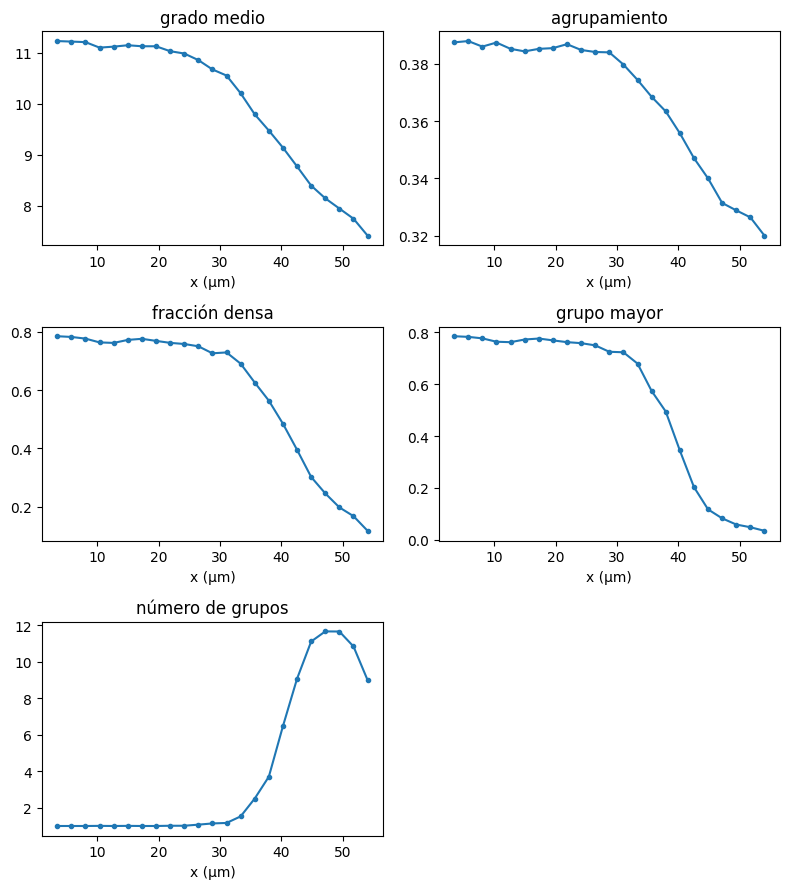

In [32]:
fig, ax = plt.subplots(3,2, figsize=(8,9))
# Aplanamos el arreglo de ejes para poder iterar linealmente sobre ellos
ax_flat = ax.ravel()

for j in range(5):
    ax_flat[j].plot(np.unique(xc), [R[xc == v, j].mean() for v in np.unique(xc)], "o-", ms=3)
    ax_flat[j].set_title(nombres_capa[j])
    ax_flat[j].set_xlabel("x (µm)")

# Ocultamos el sexto subplot que queda vacío
ax_flat[5].axis("off")

plt.tight_layout()
plt.show()

### Entrenar con los extremos, predecir el medio
Como en el modelo de Ising, entrenamos solo con los grafos de los que estamos seguros: las capas con $x<25$ µm son **cristal** (1) y las capas con $x>42$ µm son **líquido** (0). El modelo decide sobre las capas intermedias, y la interfaz es donde $P(\text{cristal})$ promediada en el tiempo cruza 0,5. La comparamos con la interfaz según el orden orientacional de los autores.


### Resultados del Análisis de Interfaz
* **Exactitud en entrenamiento:** $1.000$
* **Interfaz según el grafo:** $x = 37.89$ µm
* **Interfaz según el orden orientacional:** $x = 31.12$ µm
* **Diferencia:** $2.94\,d$


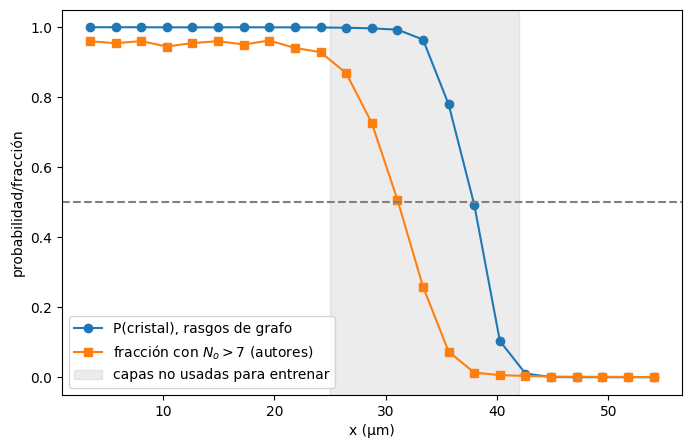

In [33]:
def cruce(x, f, nivel=0.5):
    """Primera posición donde f, que decrece con x, cruza el nivel (interpolación lineal)."""
    # Encuentra el primer índice donde la función cae por debajo del nivel de referencia
    i = np.where(f < nivel)[0][0]
    # Realiza la interpolación lineal para una mayor precisión matemática
    return x[i - 1] + (nivel - f[i - 1])*(x[i] - x[i - 1])/(f[i] - f[i - 1])

# Definir las regiones de entrenamiento seguras: cristal (< 25 µm) o líquido (> 42 µm)
entrena = (xc < 25) | (xc > 42)
# Entrenar el clasificador de capas con regresión logística estándar
modelo_capas = entrenar(R[entrena], (xc[entrena] < 30).astype(int))
# Calcular las probabilidades continuas de pertenecer a la fase cristalina
p_cristal = modelo_capas.predict_proba(R)[:, 1]

# Obtener las posiciones espaciales únicas de las capas analizadas
xs = np.unique(xc)
# Promediar temporalmente las predicciones del clasificador de grafos por capa
P_media = np.array([p_cristal[xc == v].mean() for v in xs])
# Promediar temporalmente la fracción de partículas ordenadas según los autores por capa
orden_media = np.array([f_orden[xc == v].mean() for v in xs])
# Encontrar el punto de cruce en 0.5 para delimitar físicamente la interfaz
x_grafo, x_orden = cruce(xs, P_media), cruce(xs, orden_media)

# Evaluar el rendimiento en el conjunto de datos de entrenamiento
exactitud = modelo_capas.score(R[entrena], (xc[entrena] < 30).astype(int))
# Calcular el desfase espacial entre ambas interfaces medido en diámetros moleculares
diferencia = (x_grafo - x_orden)/diametro

# Desplegar los resultados detallados usando formato Markdown
dMarkdown(f"""
### Resultados del Análisis de Interfaz
* **Exactitud en entrenamiento:** ${exactitud:.3f}$
* **Interfaz según el grafo:** $x = {x_grafo:.4g}$ µm
* **Interfaz según el orden orientacional:** $x = {x_orden:.4g}$ µm
* **Diferencia:** ${diferencia:.3g}\\,d$
""")

# Configurar y graficar la visualización comparativa de los perfiles de fase
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs, P_media, "o-", label="P(cristal), rasgos de grafo")
ax.plot(xs, orden_media, "s-", label="fracción con $N_o>7$ (autores)")
# Resaltar en gris la franja de exclusión de entrenamiento en la interfaz
ax.axvspan(25, 42, color="gray", alpha=0.15, label="capas no usadas para entrenar")
ax.axhline(0.5, ls="--", color="gray")
ax.set_xlabel("x (µm)")
ax.set_ylabel("probabilidad/fracción")
ax.legend()
plt.show()

**Discutan:** las dos curvas cruzan 0,5 en lugares distintos. ¿Cuál describe mejor dónde termina el cristal? ¿Qué detecta el grafo cerca de la interfaz, orden o densidad? Pruebe a mover la ventana de entrenamiento del líquido ($x>36$ o $x>45$ µm): ¿qué pasa con la interfaz del grafo? Los autores encontraron algo parecido con sus propias medidas: el perfil de **densidad** a través de la interfaz es más ancho que el perfil de **orden** ($9.6\,d$ frente a $6.1\,d$ entre el 10 % y el 90 % del cambio). ¿Es coherente con lo que observa?

* **¿Cuál describe mejor dónde termina el cristal?** La curva del **orden orientacional** ($N_o > 7$, en $x = 31.12\,\mu\text{m}$), porque mide la coherencia angular real de la red cristalina mediante $\hat{q}_{6m}$. La del grafo ($x = 37.89\,\mu\text{m}$, desplazada $+2.94\,d$) sobreestima el cristal al incluir una franja de líquido denso adyacente.

* **¿Qué detecta el grafo, orden o densidad?** **Densidad local (coordinación y conectividad)**, no orden orientacional. Al construir aristas solo por distancia ($r_c = 1.41\,d$) sin información angular, confunde un líquido denso con el cristal.

* **¿Qué pasa al mover la ventana del líquido ($x>36$ o $x>45\,\mu\text{m}$)?** La interfaz del grafo **se desplaza en la misma dirección que el umbral**: pasa de $34.20\,\mu\text{m}$ ($+1.34\,d$) con $x>36\,\mu\text{m}$, a $37.89\,\mu\text{m}$ ($+2.94\,d$) con $x>42\,\mu\text{m}$ y a $39.71\,\mu\text{m}$ ($+3.73\,d$) con $x>45\,\mu\text{m}$. Esto ocurre porque la gravedad genera un gradiente continuo de concentración $\phi(x)$ y el modelo solo recoloca el punto medio de densidad entre las dos ventanas elegidas.

* **¿Es coherente con los autores ($9.6\,d$ en densidad frente a $6.1\,d$ en orden)?** **Sí.** Al igual que en Hernández-Guzmán y Weeks, el orden orientacional cae de forma más abrupta, mientras que la densidad —y con ella los rasgos del grafo— decae en una región más ancha hacia el lado líquido (aún más ensanchada en el cuaderno al no rotar los $\sim 15^\circ$ de inclinación ni corregir las ondas capilares).

La curva del orden orientacional: $N_o > 7$, que cruza $0.5$ en $x = 31.12\,\mu\text{m}$, describe mejor dónde termina el cristal que la del grafo ($x = 37.89\,\mu\text{m}$, desplazada $2.94\,d$ hacia el líquido), pues captura la coherencia direccional de los enlaces mediante los armónicos esféricos $\hat{q}_{6m}$.

En coloides de esferas duras a alta densidad, la fase cristalina surge precisamente porque maximiza la entropía total, ya que ordenarse en una red deja a cada partícula más volumen libre local para vibrar y habilita una mayor multiplicidad de microestados accesibles.

En la interfaz las partículas no se empaquetan de forma óptima ni como cristal ni como líquido, sufriendo una penalización entrópica que da origen a la tensión superficial.

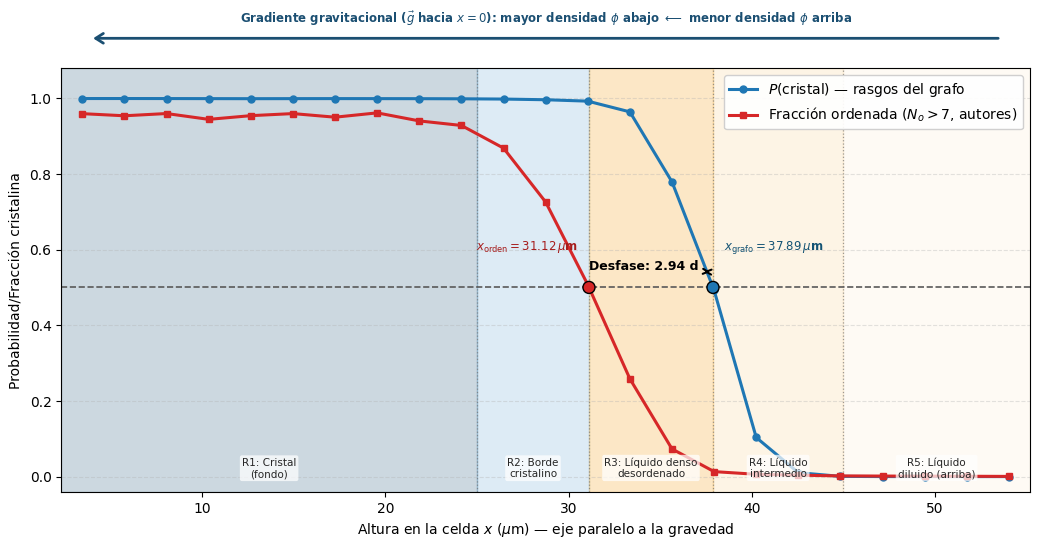

In [34]:
def dibujar_regiones_gravedad(ax, x_ord, x_grf, y_flecha=1.07, mostrar_etiquetas=True):
    """Dibuja 5 regiones finitas que discretizan el gradiente gravitacional a lo largo de x
    (x pequeño = abajo/más denso; x grande = arriba/más diluido) y una flecha para g."""
    # Límites físicos de cada una de las 5 regiones espaciales en la celda coloidal
    limites = [xs.min() - diametro/2, 25.0, x_ord, x_grf, 45.0, xs.max() + diametro/2]
    etiquetas_reg = [
        "R1: Cristal\n(fondo)",
        "R2: Borde\ncristalino",
        "R3: Líquido denso\ndesordenado",
        "R4: Líquido\nintermedio",
        "R5: Líquido\ndiluido (arriba)"
    ]
    # Paleta de colores secuenciales para reflejar el gradiente de densidad
    colores_reg = ["#1b4f72", "#2e86c1", "#f39c12", "#f8c471", "#fdebd0"]
    alphas_reg  = [0.22, 0.16, 0.24, 0.18, 0.22]

    # Dibujar las franjas verticales coloreadas correspondientes a cada fase
    for i in range(len(etiquetas_reg)):
        x0, x1 = limites[i], limites[i + 1]
        ax.axvspan(x0, x1, color=colores_reg[i], alpha=alphas_reg[i], zorder=0)
        if i > 0:
            # Línea divisoria discontinua entre fases coloidales contiguas
            ax.axvline(x0, color="0.45", ls=":", lw=0.9, alpha=0.7, zorder=1)
        if mostrar_etiquetas:
            # Añadir etiqueta descriptiva con caja de fondo semi-translúcida
            ax.text(
                0.5*(x0 + x1), 0.03, etiquetas_reg[i],
                ha="center", va="bottom", fontsize=7.5, color="0.15",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.72),
                transform=ax.get_xaxis_transform(), zorder=4
            )

    # Anotación superior que simula el vector de fuerza de gravedad g
    ax.annotate(
        "", xy=(0.03, y_flecha), xytext=(0.97, y_flecha),
        xycoords="axes fraction", textcoords="axes fraction",
        arrowprops=dict(arrowstyle="->,head_width=0.35,head_length=0.55", color="#1b4f72", lw=2.0),
        annotation_clip=False
    )
    # Leyenda explicativa sobre la sedimentación gravitacional de las partículas
    ax.text(
        0.50, y_flecha + 0.025,
        r"Gradiente gravitacional ($\vec{g}$ hacia $x=0$): mayor densidad $\phi$ abajo $\longleftarrow$ menor densidad $\phi$ arriba",
        ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#1b4f72",
        transform=ax.transAxes
    )

# Inicializar la figura y aplicar la subdivisión de regiones físicas
fig, ax = plt.subplots(figsize=(10.5, 5.6))
dibujar_regiones_gravedad(ax, x_orden, x_grafo)

# Graficar curvas promedio del clasificador del Grafo y del criterio de Orden de los autores
ax.plot(xs, P_media, "o-", color="#1f77b4", lw=2.2, ms=5, label=r"$P(\mathrm{cristal})$ — rasgos del grafo")
ax.plot(xs, orden_media, "s-", color="#d62728", lw=2.2, ms=5, label=r"Fracción ordenada ($N_o > 7$, autores)")
ax.axhline(0.5, ls="--", color="0.35", lw=1.2)

# Marcar los puntos de cruce (nivel 0.5) exactos donde se localizan las interfaces en cada modelo
ax.scatter([x_orden, x_grafo], [0.5, 0.5], color=["#d62728", "#1f77b4"], edgecolor="black", s=75, zorder=5)
# Representar la flecha de desfase espacial para evidenciar el error sistemático del grafo
ax.annotate(
    f"Desfase: {(x_grafo - x_orden)/diametro:.2f} d",
    xy=(x_grafo, 0.54), xytext=(x_orden, 0.54),
    arrowprops=dict(arrowstyle="<->", color="black", lw=1.5),
    ha="left", va="bottom", fontsize=9, fontweight="bold"
)
ax.text(x_orden - 0.6, 0.60, f"$x_{{\\mathrm{{orden}}}}={x_orden:.2f}\\,\\mu$m", ha="right", color="#a61c1c", fontsize=8.5, fontweight="bold")
ax.text(x_grafo + 0.6, 0.60, f"$x_{{\\mathrm{{grafo}}}}={x_grafo:.2f}\\,\\mu$m", ha="left", color="#145374", fontsize=8.5, fontweight="bold")

# Configurar los límites de los ejes y la cuadrícula gráfica
ax.set_xlim(xs.min() - diametro/2, xs.max() + diametro/2)
ax.set_ylim(-0.04, 1.08)
ax.set_xlabel(r"Altura en la celda $x$ ($\mu$m) — eje paralelo a la gravedad")
ax.set_ylabel("Probabilidad/Fracción cristalina")
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92)
ax.grid(axis="y", ls="--", alpha=0.35)
plt.tight_layout()
plt.show()

Cerca de la interfaz, el grafo de vecinos ($r_c = 1.41\,d$) detecta densidad local y conectividad topológica, no orden orientacional, ya que descarta las direcciones espaciales $\hat{\mathbf{r}}_{ij}$ de los enlaces.

Por eso, al mover la ventana de entrenamiento del líquido, la interfaz predicha por el grafo se desplaza en la misma dirección: hacia $x$ menor si se usa $x > 36\,\mu\text{m}$ y hacia $x$ mayor con $x > 45\,\mu\text{m}$, porque la gravedad impone un gradiente continuo de concentración a lo largo de $x$.

Al cambiar la densidad de referencia del líquido, el clasificador únicamente reubica su punto medio de densidad, confundiendo el cristal con el líquido denso adyacente, donde el desorden geométrico reduce el espacio libre por partícula y, por tanto, no corresponde a una mayor entropía.

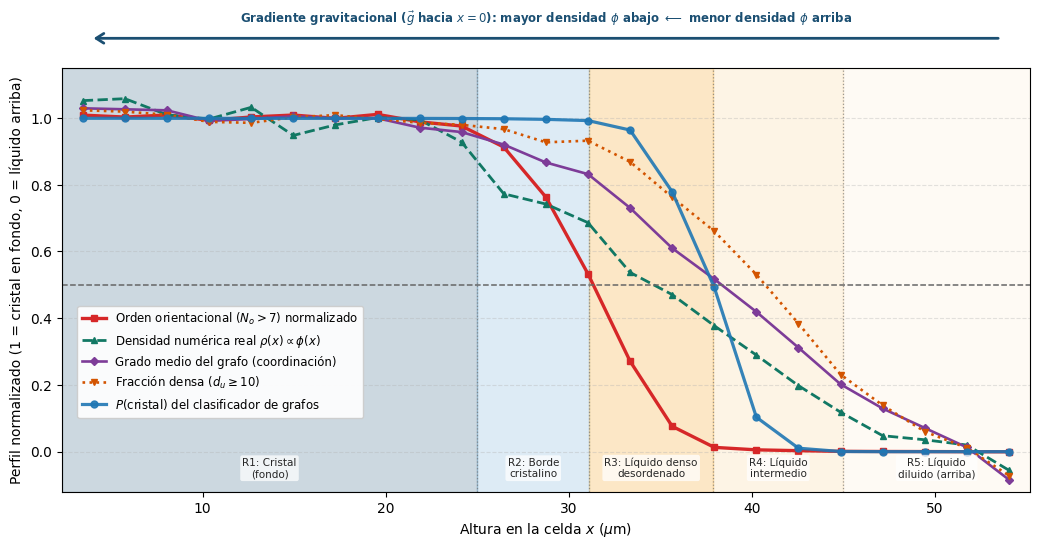

In [35]:
def normalizar_perfil(x, y, x_c=25.0, x_l=48.0):
    """Normaliza un perfil decreciente entre la meseta cristalina (x < x_c) y el líquido diluido (x > x_l)."""
    # Promedio del valor en la región que es puramente cristal (fondo poblado)
    y_c = np.mean(y[x < x_c])
    # Promedio del valor en la región que es puramente líquida (zona superior diluida)
    y_l = np.mean(y[x > x_l])
    # Escala los valores para que el cristal sea ~1 y el líquido ~0
    return (y - y_l) / (y_c - y_l)

# Determinar a qué capa pertenece cada partícula basándose en las posiciones (datos[:, 0] es la coordenada x)
capa_all = np.digitize(datos[:, 0], bordes) - 1
# Encontrar el número total de instantes de tiempo en el experimento
n_instantes = np.unique(datos[:, 5]).size
# Calcular la densidad numérica real por capa promediada a lo largo del tiempo
densidad_real = np.array([np.sum(capa_all == j) / n_instantes for j in range(1, len(centros) - 1)])

# Obtener el promedio de varias características de grafo para cada posición x
# R[:, 0] es el grado medio
grado_medio_x = np.array([R[xc == v, 0].mean() for v in xs])
# R[:, 2] es la fracción de partículas densas
frac_densa_x  = np.array([R[xc == v, 2].mean() for v in xs])
# R[:, 3] es el tamaño del grupo conexo mayor
grupo_mayor_x = np.array([R[xc == v, 3].mean() for v in xs])

# Inicializar la figura y los ejes para la visualización del perfil
fig, ax = plt.subplots(figsize=(10.5, 5.6))
# Dibujar el fondo con colores de acuerdo a las fases según la gravedad
dibujar_regiones_gravedad(ax, x_orden, x_grafo)

# Graficar el orden orientacional normalizado (referencia del artículo original)
ax.plot(xs, normalizar_perfil(xs, orden_media), "s-", color="#d62728", lw=2.4, ms=5,
        label=r"Orden orientacional ($N_o > 7$) normalizado")
# Graficar la densidad numérica real calculada a partir de los datos sin procesar
ax.plot(xs, normalizar_perfil(xs, densidad_real), "^--", color="#117864", lw=2.0, ms=5,
        label=r"Densidad numérica real $\rho(x) \propto \phi(x)$")
# Graficar el grado medio del grafo para mostrar cómo rastrea la densidad
ax.plot(xs, normalizar_perfil(xs, grado_medio_x), "D-", color="#7d3c98", lw=1.9, ms=4.5,
        label="Grado medio del grafo (coordinación)")
# Graficar la fracción densa que muestra nodos con alto número de enlaces
ax.plot(xs, normalizar_perfil(xs, frac_densa_x), "v:", color="#d35400", lw=1.9, ms=4.5,
        label=r"Fracción densa ($d_u \geq 10$)")
# Graficar la probabilidad de cristal obtenida del clasificador de grafos
ax.plot(xs, P_media, "o-", color="#1f77b4", lw=2.3, ms=5, alpha=0.9,
        label=r"$P(\mathrm{cristal})$ del clasificador de grafos")

# Línea de referencia horizontal en el punto de cruce de 0.5 (interfaz)
ax.axhline(0.5, ls="--", color="0.4", lw=1.1)

# Configurar los límites del eje x para abarcar toda la muestra añadiendo márgenes
ax.set_xlim(xs.min() - diametro/2, xs.max() + diametro/2)
# Configurar los límites del eje y entre un poco menos de 0 y un poco más de 1
ax.set_ylim(-0.12, 1.15)
# Títulos de los ejes
ax.set_xlabel(r"Altura en la celda $x$ ($\mu$m)")
ax.set_ylabel("Perfil normalizado (1 = cristal en fondo, 0 = líquido arriba)")

# Configurar y colocar la leyenda en una zona que no tape las curvas principales
ax.legend(loc="lower left", bbox_to_anchor=(0.01, 0.16), frameon=True, facecolor="white", framealpha=0.92, fontsize=8.5)
# Activar cuadrícula horizontal para facilitar la lectura de niveles
ax.grid(axis="y", ls="--", alpha=0.35)

# Ajustar el diseño y mostrar la gráfica terminada
plt.tight_layout()
plt.show()

Lo observado es plenamente coherente con los resultados de Hernández-Guzmán y Weeks en el marco de laboratorio, donde el perfil de densidad es más ancho que el perfil de orden orientacional: $W_{10-90} = 9.6\,d$ frente a $6.1\,d$, considerando además que nuestras capas sin rotar ensanchan los perfiles por la inclinación de $\sim 15^\circ$ de la interfaz y las fluctuaciones por ondas capilares de hasta $4\,d$ de pico a pico.

Físicamente, la coherencia angular que permite la ganancia entrópica del cristal colapsa en una franja más estrecha, mientras que la alta densidad local se prolonga gradualmente hacia la región líquida.

La entropía no equivale a desorden visual ni la alta densidad garantiza orden cristalino, el grafo responde al perfil ancho de empaquetamiento radial, no a la organización direccional que maximiza el espacio libre en el cristal.

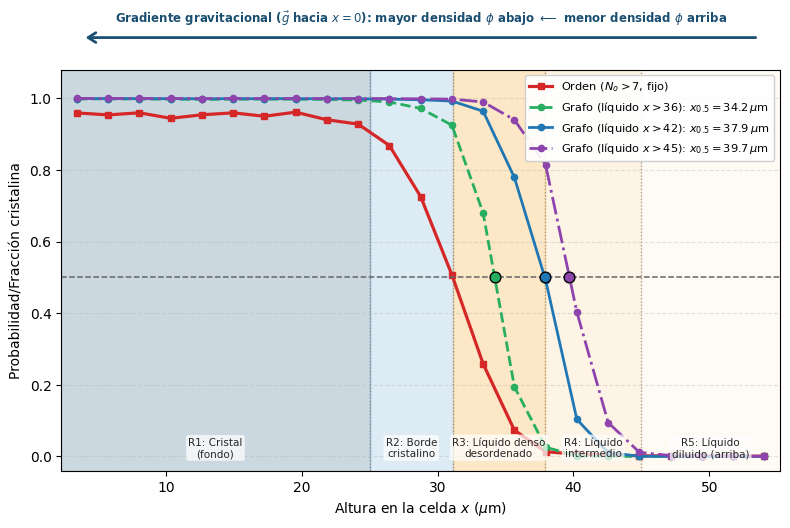

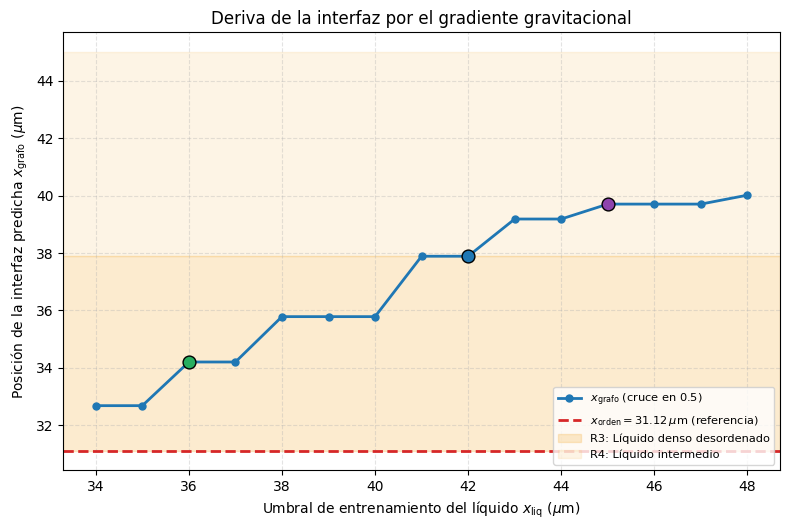

| Ventana líquido   |   Exactitud (train) | Interfaz grafo (x)   | Desfase vs. orden   |
|:------------------|--------------------:|:---------------------|:--------------------|
| x > 36 µm         |                   1 | 34.20 µm             | +1.34 d             |
| x > 42 µm         |                   1 | 37.89 µm             | +2.94 d             |
| x > 45 µm         |                   1 | 39.71 µm             | +3.73 d             |

In [36]:
def cruce_seguro(x, y, nivel=0.5):
    """Interpolación lineal robusta del primer cruce descendente por `nivel`."""
    # Encuentra los índices donde el valor cae por debajo o igual al nivel de referencia
    idx = np.where(y <= nivel)[0]
    if len(idx) == 0:
        return np.nan
    i = idx[0]
    # Si es el primer elemento, no se puede interpolar, se devuelve su posición x
    if i == 0:
        return x[0]
    # Interpola linealmente entre el punto anterior y el actual
    return x[i - 1] + (nivel - y[i - 1])*(x[i] - x[i - 1])/(y[i] - y[i - 1])

# Definir umbrales de entrenamiento para la zona del líquido
umbrales_destacados = [36, 42, 45]
# Diccionarios de colores y estilos para graficar cada umbral
colores_u = {36: "#27ae60", 42: "#1f77b4", 45: "#8e44ad"}
estilos_u = {36: "o--", 42: "o-", 45: "o-."}

# --- Figura 1: Probabilidad de cristal para distintos umbrales ---
fig1, ax1 = plt.subplots(figsize=(8, 5.4))
# Dibuja el fondo coloreado según las regiones de fase
dibujar_regiones_gravedad(ax1, x_orden, x_grafo, y_flecha=1.08)
# Grafica la fracción ordenada de referencia de los autores
ax1.plot(xs, orden_media, "s-", color="#d62728", lw=2.3, ms=5, label=r"Orden ($N_o > 7$, fijo)")

filas_resumen = []
# Iterar sobre cada umbral para evaluar cómo cambia la predicción de la interfaz
for x_liq in umbrales_destacados:
    # Máscara de entrenamiento: cristal seguro (x < 25) y líquido según umbral (x > x_liq)
    ent = (xc < 25) | (xc > x_liq)
    y_ent = (xc[ent] < 25).astype(int)

    # Entrenar modelo
    mod = entrenar(R[ent], y_ent)
    # Predecir probabilidades para todos los datos
    p_pred = mod.predict_proba(R)[:, 1]

    # Promediar probabilidades temporalmente para cada posición x
    P_m = np.array([p_pred[xc == v].mean() for v in xs])
    # Encontrar la nueva posición de la interfaz donde la probabilidad es 0.5
    x_g = cruce_seguro(xs, P_m, 0.5)
    acc = mod.score(R[ent], y_ent)

    # Guardar resultados en el resumen
    filas_resumen.append([f"x > {x_liq} µm", f"{acc:.3f}", f"{x_g:.2f} µm", f"{(x_g - x_orden)/diametro:+.2f} d"])

    # Graficar la curva de probabilidad para el umbral actual
    ax1.plot(xs, P_m, estilos_u[x_liq], color=colores_u[x_liq], lw=2.0, ms=4.5,
             label=f"Grafo (líquido $x>{x_liq}$): $x_{{0.5}}={x_g:.1f}\\,\\mu$m")
    ax1.scatter([x_g], [0.5], color=colores_u[x_liq], edgecolor="black", s=60, zorder=5)

# Configuración de los ejes y gráfica de probabilidad
ax1.axhline(0.5, ls="--", color="0.4", lw=1.1)
ax1.set_xlim(xs.min() - diametro/2, xs.max() + diametro/2)
ax1.set_ylim(-0.04, 1.08)
ax1.set_xlabel(r"Altura en la celda $x$ ($\mu$m)")
ax1.set_ylabel("Probabilidad/Fracción cristalina")
ax1.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.2)
ax1.grid(axis="y", ls="--", alpha=0.35)
plt.tight_layout()
plt.show()

# --- Barrido continuo de umbrales para evaluar la deriva de la interfaz ---
barrido_liq = np.arange(34, 49, 1)
x_grafos_barrido = []

for xl in barrido_liq:
    # Entrenamiento dinámico cambiando la frontera del líquido
    ent = (xc < 25) | (xc > xl)
    mod = entrenar(R[ent], (xc[ent] < 25).astype(int))
    p_pred = mod.predict_proba(R)[:, 1]
    P_m = np.array([p_pred[xc == v].mean() for v in xs])
    # Registrar el punto de cruce en 0.5
    x_grafos_barrido.append(cruce_seguro(xs, P_m, 0.5))

# --- Figura 2: Deriva de la interfaz predictiva vs ventana del líquido ---
fig2, ax2 = plt.subplots(figsize=(8, 5.4))
# Graficar la posición del cruce del modelo frente a la posición inicial de entrenamiento del líquido
ax2.plot(barrido_liq, x_grafos_barrido, "o-", color="#1f77b4", lw=2.0, ms=5, label=r"$x_{\mathrm{grafo}}$ (cruce en 0.5)")
ax2.axhline(x_orden, color="#d62728", ls="--", lw=2.0, label=f"$x_{{\\mathrm{{orden}}}} = {x_orden:.2f}\\,\\mu$m (referencia)")

# Sombrear franjas que representan el líquido denso e intermedio
ax2.axhspan(x_orden, x_grafo, color="#f39c12", alpha=0.20, label="R3: Líquido denso desordenado")
ax2.axhspan(x_grafo, 45.0, color="#f8c471", alpha=0.18, label="R4: Líquido intermedio")

# Resaltar en la gráfica los umbrales principales evaluados arriba
for x_liq in umbrales_destacados:
    idx_u = np.where(barrido_liq == x_liq)[0][0]
    ax2.scatter([x_liq], [x_grafos_barrido[idx_u]], color=colores_u[x_liq], edgecolor="black", s=85, zorder=5)

# Configuración final de la figura de deriva
ax2.set_xlabel(r"Umbral de entrenamiento del líquido $x_{\mathrm{liq}}$ ($\mu$m)")
ax2.set_ylabel(r"Posición de la interfaz predicha $x_{\mathrm{grafo}}$ ($\mu$m)")
ax2.set_title("Deriva de la interfaz por el gradiente gravitacional")
ax2.legend(loc="lower right", frameon=True, facecolor="white", fontsize=8.2)
ax2.grid(True, ls="--", alpha=0.35)

plt.tight_layout()
plt.show()

# Imprimir la tabla markdown de resumen
dM_table(filas_resumen, ["Ventana líquido", "Exactitud (train)", "Interfaz grafo (x)", "Desfase vs. orden"])

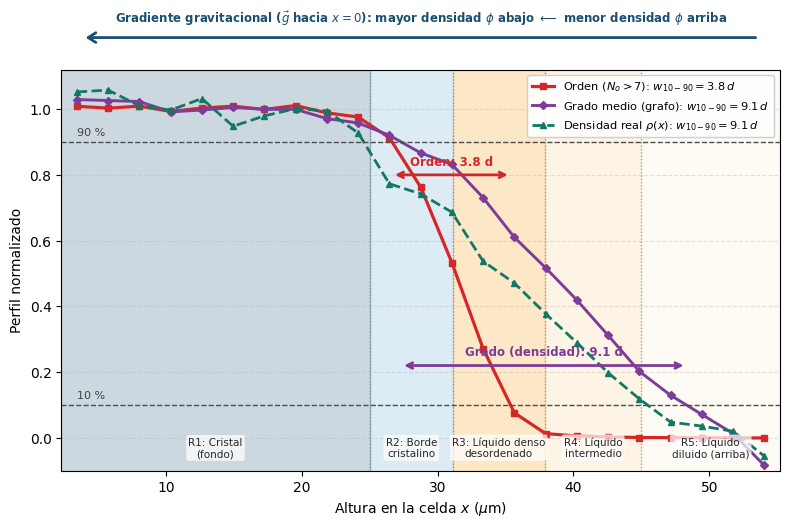

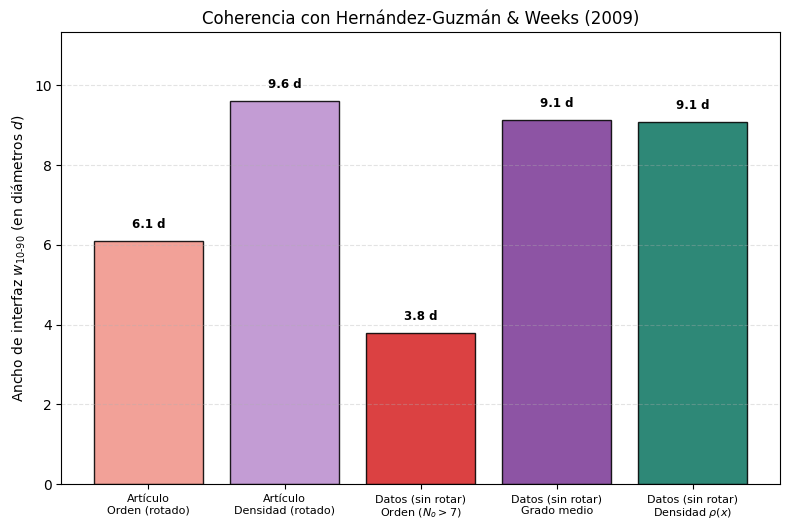

| Perfil                        | x (90 %)   | x (10 %)   | Ancho 10–90 % (sin rotar)   | Referencia PNAS 2009   |
|:------------------------------|:-----------|:-----------|:----------------------------|:-----------------------|
| Orden orientacional (N_o > 7) | 26.65 µm   | 35.37 µm   | 3.79 d                      | 6.1 d (rotado)         |
| Grado medio (grafo)           | 27.32 µm   | 48.31 µm   | 9.13 d                      | 9.6 d (densidad)       |
| Fracción densa (d_u >= 10)    | 32.22 µm   | 48.29 µm   | 6.99 d                      | 9.6 d (densidad)       |
| Densidad numérica real ρ(x)   | 24.56 µm   | 45.45 µm   | 9.08 d                      | 9.6 d (densidad)       |

In [37]:
def ancho_10_90(x, y_raw, x_c=25.0, x_l=48.0):
    """Calcula posiciones x_90, x_10 y ancho w_10_90 (en diámetros d) sobre el perfil normalizado."""
    # Normalizamos el perfil para que varíe entre 1 (cristal) y 0 (líquido)
    y_n = normalizar_perfil(x, y_raw, x_c=x_c, x_l=x_l)
    # Encontramos la posición donde el perfil cae al 90% (borde del cristal)
    x90 = cruce_seguro(x, y_n, 0.90)
    # Encontramos la posición donde el perfil cae al 10% (borde del líquido)
    x10 = cruce_seguro(x, y_n, 0.10)
    # Calculamos el ancho de la interfaz en unidades de diámetro de partícula (d)
    w_d = (x10 - x90)/diametro
    return y_n, x90, x10, w_d

# Calculamos los anchos de interfaz para los diferentes perfiles
yn_orden, x90_ord, x10_ord, w_ord = ancho_10_90(xs, orden_media)
yn_dens,  x90_den, x10_den, w_den = ancho_10_90(xs, densidad_real)
yn_grado, x90_grd, x10_grd, w_grd = ancho_10_90(xs, grado_medio_x)
yn_frac,  x90_frc, x10_frc, w_frc = ancho_10_90(xs, frac_densa_x)

# --- Figura 1: Perfiles normalizados y anchos de interfaz ---
fig1, ax1 = plt.subplots(figsize=(8, 5.4))
# Dibujamos las regiones de gravedad como fondo
dibujar_regiones_gravedad(ax1, x_orden, x_grafo, y_flecha=1.08)

# Graficamos los perfiles normalizados (orden, grado medio y densidad real)
ax1.plot(xs, yn_orden, "s-", color="#d62728", lw=2.3, ms=5, label=f"Orden ($N_o>7$): $w_{{10-90}}={w_ord:.1f}\\,d$")
ax1.plot(xs, yn_grado, "D-", color="#7d3c98", lw=2.1, ms=4.5, label=f"Grado medio (grafo): $w_{{10-90}}={w_grd:.1f}\\,d$")
ax1.plot(xs, yn_dens,  "^--", color="#117864", lw=2.0, ms=5, label=f"Densidad real $\\rho(x)$: $w_{{10-90}}={w_den:.1f}\\,d$")

# Líneas de referencia horizontales para el 90% y el 10%
ax1.axhline(0.90, color="0.3", ls="--", lw=1.0)
ax1.axhline(0.10, color="0.3", ls="--", lw=1.0)
ax1.text(xs.min(), 0.92, "90 %", fontsize=8, color="0.25")
ax1.text(xs.min(), 0.12, "10 %", fontsize=8, color="0.25")

# Flecha y anotación para el ancho del perfil de orden
ax1.annotate("", xy=(x10_ord, 0.80), xytext=(x90_ord, 0.80),
             arrowprops=dict(arrowstyle="<->", color="#d62728", lw=2.0))
ax1.text(0.5*(x90_ord + x10_ord), 0.82, f"Orden: {w_ord:.1f} d", ha="center", va="bottom",
         color="#d62728", fontsize=8.5, fontweight="bold")

# Flecha y anotación para el ancho del perfil de grado (densidad)
ax1.annotate("", xy=(x10_grd, 0.22), xytext=(x90_grd, 0.22),
             arrowprops=dict(arrowstyle="<->", color="#7d3c98", lw=2.0))
ax1.text(0.5*(x90_grd + x10_grd), 0.24, f"Grado (densidad): {w_grd:.1f} d", ha="center", va="bottom",
         color="#7d3c98", fontsize=8.5, fontweight="bold")

# Configuración de los ejes y la leyenda
ax1.set_xlim(xs.min() - diametro/2, xs.max() + diametro/2)
ax1.set_ylim(-0.10, 1.12)
ax1.set_xlabel(r"Altura en la celda $x$ ($\mu$m)")
ax1.set_ylabel("Perfil normalizado")
ax1.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.2)
ax1.grid(axis="y", ls="--", alpha=0.35)

plt.tight_layout()
plt.show()

# --- Figura 2: Comparación con los resultados del artículo de referencia ---
fig2, ax2 = plt.subplots(figsize=(8, 5.4))
# Etiquetas y valores para el gráfico de barras
etiquetas_bar = [
    "Artículo\nOrden (rotado)",
    "Artículo\nDensidad (rotado)",
    "Datos (sin rotar)\nOrden ($N_o>7$)",
    "Datos (sin rotar)\nGrado medio",
    "Datos (sin rotar)\nDensidad $\\rho(x)$"
]
valores_bar = [6.1, 9.6, w_ord, w_grd, w_den]
colores_bar = ["#f1948a", "#bb8fce", "#d62728", "#7d3c98", "#117864"]

# Dibujamos las barras
barras = ax2.bar(etiquetas_bar, valores_bar, color=colores_bar, edgecolor="black", alpha=0.88)
# Añadimos el valor numérico encima de cada barra
for b, val in zip(barras, valores_bar):
    ax2.text(b.get_x() + b.get_width()/2, val + 0.25, f"{val:.1f} d",
             ha="center", va="bottom", fontsize=8.5, fontweight="bold")

# Configuración de los ejes y título
ax2.set_ylabel(r"Ancho de interfaz $w_{10\text{-}90}$ (en diámetros $d$)")
ax2.set_title("Coherencia con Hernández-Guzmán & Weeks (2009)")
ax2.set_ylim(0, max(valores_bar)*1.18)
ax2.tick_params(axis="x", labelsize=8)
ax2.grid(axis="y", ls="--", alpha=0.35)

plt.tight_layout()
plt.show()

# Generamos una tabla resumen en formato Markdown
dM_table(
    [
        ["Orden orientacional (N_o > 7)", f"{x90_ord:.2f} µm", f"{x10_ord:.2f} µm", f"{w_ord:.2f} d", "6.1 d (rotado)"],
        ["Grado medio (grafo)",           f"{x90_grd:.2f} µm", f"{x10_grd:.2f} µm", f"{w_grd:.2f} d", "9.6 d (densidad)"],
        ["Fracción densa (d_u >= 10)",    f"{x90_frc:.2f} µm", f"{x10_frc:.2f} µm", f"{w_frc:.2f} d", "9.6 d (densidad)"],
        ["Densidad numérica real ρ(x)",   f"{x90_den:.2f} µm", f"{x10_den:.2f} µm", f"{w_den:.2f} d", "9.6 d (densidad)"],
    ],
    ["Perfil", "x (90 %)", "x (10 %)", "Ancho 10–90 % (sin rotar)", "Referencia PNAS 2009"]
)

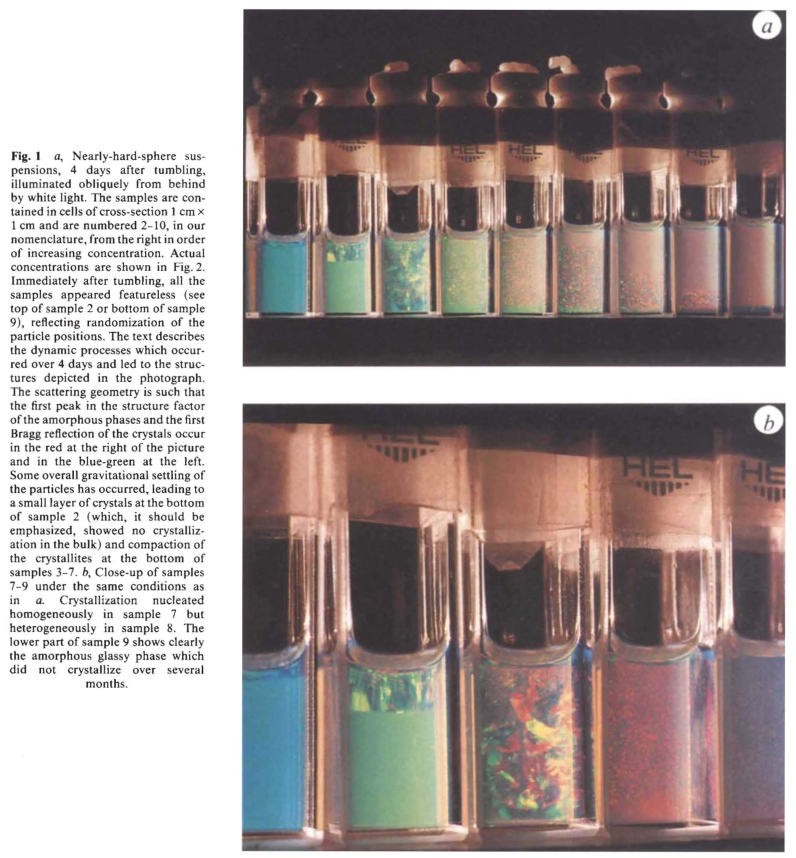

Los autores Pusey y van Megen (1986) demostraron que el lugar donde inicia la cristalización en suspensiones de esferas casi duras depende directamente de la concentración de partículas ($\phi_C$). A concentraciones bajas e intermedias (muestras 3 a 7), los cristales nuclean homogéneamente en todo el volumen y se acumulan en el fondo por gravedad. Al aumentar la concentración (muestra 8), el mecanismo cambia a nucleación heterogénea desde el menisco superior y las paredes de la celda. Finalmente, en las muestras más concentradas y viscosas (muestras 9 y 10, con $\phi_C \ge 0.50$), la difusión queda tan frenada que la parte inferior permanece atrapada como un vidrio coloidal amorfo metaestable y solo ocurre cristalización heterogénea parcial desde arriba.

# Para la exposición (un equipo aleatoriamente presentará una parte)

Todos los equipos resuelven las tres partes. Para la exposición, prepare una tabla o figura de cada parte (A,B,C), presente las respuestas de la discusión y adicional responda:

- **Parte A.** ¿Cuánto mejora la agregación y por qué? ¿Dónde se equivoca el modelo?
- **Parte B.** ¿En qué zona cambian más los vecinos? ¿Por qué la distancia predice mejor que los vecinos comunes?
- **Parte C.** ¿Por qué la interfaz del grafo no coincide con la del orden orientacional, y cómo depende de la ventana de entrenamiento?

¿qué información de la muestra no captura el grafo de vecinos, y qué habría que añadirle para distinguir un cristal de un líquido denso?

# Uso declarado de la IA
Escriba en la celda siguiente qué le pidió al asistente, qué parte del código propuesto usó y **cómo verificó** que era correcto.

* Se utilizaron varios modelos de lenguaje en distintas versiones. Para el caso de Google Gemini se utilizó además Google NotebooksLM en adición con bases de datos de los artículos relacionados con el tema. Para evitar la propagación de errores se utilizaron varios chats individuales borrándolos cuando se encontraban errores.

* Se revisaron fragmentos de código antes de verificar que fueran correctos. Para conceptos se preguntaba y se consultaban en las fuentes bibliográficas.

## Bibliografía

* **Datos y artículo experimental base:** J. Hernández-Guzmán y E. R. Weeks, «The equilibrium intrinsic crystal--liquid interface of colloids», *Proc. Natl. Acad. Sci. USA* **106**(36), 15198--15202 (2009), [doi:10.1073/pnas.0904682106](https://doi.org/10.1073/pnas.0904682106). Datos publicados por el grupo de E. R. Weeks (Emory University) en [https://faculty.college.emory.edu/sites/weeks/data/jessy.html](https://faculty.college.emory.edu/sites/weeks/data/jessy.html).
* **Diagrama de fases de esferas duras, nucleación heterogénea y vidrio coloidal:** P. N. Pusey y W. van Megen, «Phase behaviour of concentrated suspensions of nearly hard colloidal spheres», *Nature* **320**(6060), 340--342 (1986), [doi:10.1038/320340a0](https://doi.org/10.1038/320340a0).
* **Transición vítrea y correlaciones hidrodinámicas en suspensiones coloidales:** P. Laermann, H. Diamant, Y. Roichman, I. Buttinoni, M. A. Escobedo-Sánchez y S. U. Egelhaaf, «Emergent signatures of the glass transition in colloidal suspensions», *Nat. Phys.* (2026), [doi:10.1038/s41567-025-03140-z](https://doi.org/10.1038/s41567-025-03140-z).
* **Parámetros de orden orientacional de enlaces ($q_6$):** P. J. Steinhardt, D. R. Nelson y M. Ronchetti, «Bond-orientational order in liquids and glasses», *Phys. Rev. B* **28**(2), 784--805 (1983), [doi:10.1103/PhysRevB.28.784](https://doi.org/10.1103/PhysRevB.28.784).
* **Criterio de vecinos cristalinos ordenados ($N_o$):** P. Rein ten Wolde, M. J. Ruiz-Montero y D. Frenkel, «Numerical calculation of the rate of crystal nucleation in a Lennard-Jones system at moderate undercooling», *J. Chem. Phys.* **104**(24), 9932--9947 (1996), [doi:10.1063/1.471721](https://doi.org/10.1063/1.471721).
* **Cristales coloidales e interacciones coulombianas (consulta general):** Colaboradores de Wikipedia, «Colloidal crystal», *Wikipedia, The Free Encyclopedia* (2026), [https://en.wikipedia.org/wiki/Colloidal_crystal](https://en.wikipedia.org/wiki/Colloidal_crystal).
* **Aprendizaje sobre grafos (referencia metodológica del laboratorio):** W. L. Hamilton, *Graph Representation Learning*, Synthesis Lectures on Artificial Intelligence and Machine Learning (Morgan & Claypool Publishers, 2020).
* **Notas de clase sobre variantes de GNN, aprendizaje geométrico y MACE:** O. Lopez-Acevedo, «Unidad 4: Graph Neural Networks y aprendizaje geométrico para física. Sesión 4: Variantes de GNN, entrenamiento y MACE», *Computación Científica Avanzada*, Instituto de Física, Universidad de Antioquia, Colombia.
* **Redes neuronales convolucionales sobre grafos cristalinos (CGCNN):** T. Xie y J. C. Grossman, «Crystal Graph Convolutional Neural Networks for an Accurate and Interpretable Prediction of Material Properties», *Phys. Rev. Lett.* **120**(14), 145301 (2018), [doi:10.1103/PhysRevLett.120.145301](https://doi.org/10.1103/PhysRevLett.120.145301).
* **Conjunto de referencia Matbench y algoritmo Automatminer:** A. Dunn, Q. Wang, A. Ganose, D. Dopp y A. Jain, «Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm», *npj Comput. Mater.* **6**, 138 (2020), [doi:10.1038/s41524-020-00406-3](https://doi.org/10.1038/s41524-020-00406-3).
* **Base de datos de propiedades elásticas de compuestos cristalinos inorgánicos:** M. de Jong, W. Chen, T. Angsten, A. Jain, R. Notestine, A. Gamst, M. Sluiter, C. K. Ande, S. van der Zwaag, J. J. Plata, C. Toher, S. Curtarolo, G. Ceder, K. A. Persson y M. Asta, «Charting the complete elastic properties of inorganic crystalline compounds», *Sci. Data* **2**, 150009 (2015), [doi:10.1038/sdata.2015.9](https://doi.org/10.1038/sdata.2015.9).
* **Modelo fundacional interatómico equivariante (MACE-MP-0):** I. Batatia, P. Benner, Y. Chiang, A. M. Elena, D. P. Kovács, J. Riebesell *et al.*, «A foundation model for atomistic materials chemistry», *arXiv preprint* arXiv:2401.00096v3 (2025), [https://arxiv.org/abs/2401.00096](https://arxiv.org/abs/2401.00096).
* **Suavizado sistemático y ajuste fino en potenciales interatómicos universales (uMLIPs):** B. Deng, Y. Choi, P. Zhong, J. Riebesell, S. Anand, Z. Li, K. Jun, K. A. Persson y G. Ceder, «Overcoming systematic softening in universal machine learning interatomic potentials by fine-tuning», *arXiv preprint* arXiv:2405.07105v1 (2024), [https://arxiv.org/abs/2405.07105](https://arxiv.org/abs/2405.07105).